<a href="https://colab.research.google.com/github/LielUziahu/S_Pistillata_Bet-Hedging/blob/main/Larval_Baseline_Physiology.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Global Styling & Setup
Imports the required data science packages and sets the visual fingerprint (fonts, colors, and line weights) so the final plot perfectly matches previous  figures.

In [247]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --- GLOBAL PLOT STYLING ---
# Call set_theme first so it does not overwrite custom rcParams updates
sns.set_theme(style="white", font="serif")

plt.rcParams.update({
    "font.family": "Serif",
    "font.size": 14,          # Global text size
    "axes.titlesize": 16,     # Plot titles
    "axes.titleweight": "bold", # Global title fontweight
    "axes.titlepad": 20,      # Global title padding
    "axes.labelsize": 15,     # Axis labels size
    "axes.labelweight": "bold", # Make axis labels bold
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.edgecolor": "black",
    "axes.linewidth": 2,     # Thick borders for high-contrast visibility
    "svg.fonttype": "none"    # Protects text vectors for journal export
})

# --- GLOBAL COLOR PALETTE & PLOT ARTIFACTS ---
variant_colors = {'HF': '#2ca02c', 'NF': '#d62728'}
global_box_width = 0.4
global_fig_size = (6, 6)
global_jitter = 0.1
global_marker_size = 5
global_alpha = 0.6

# Centralized Asterisk & Significance Settings
global_asterisk_size = 18
global_asterisk_weight = 'bold'

# Added for significance mapping
def get_significance_label(p):
    if p < 0.001:
        return '***'
    elif p < 0.005:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'n.s.'

# Added for cleaner look
global_y_nbins = 3
global_edgecolor = 'black'
global_line_width = 1.5

print(f"Global styling initialized with bold axis labels.")

Global styling initialized with bold axis labels.


# Release Pattarn by morph

## Block 1: Data Loading & Filtering
We need to load the Release_Data.csv and focus strictly on the HF vs NF comparison, ignoring the 'PF' (if present) to keep the comparison clean.

In [248]:
# Load the data
df = pd.read_csv('Release_Data.csv')

# Keep all data, including 'PF'
df_filtered = df.copy()

# Print the data to double-check
print("Data Preview:")
print(df_filtered.head())
print("\nUnique Morphs in Dataset:", df_filtered['morph'].unique().tolist())

Data Preview:
  colony morph  total released  % from total coloney
0      A    HF             199             50.636132
1      A    PF             164             41.730280
2      A    NF              30              7.633588
3      B    HF              23             39.655172
4      B    PF              22             37.931034

Unique Morphs in Dataset: ['HF', 'PF', 'NF']


## Block 3: Normality-Driven Statistical Engine
It checks the distribution of the differences between HF and NF, which is the correct statistical approach for paired data.

In [249]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.anova import AnovaRM
from statsmodels.stats.multitest import multipletests

print("--- COMPREHENSIVE REPEATED MEASURES ANALYSIS FOR THREE MORPHS ---")

# 1. Descriptive Statistics
print("\n1. Descriptive Statistics (% from total colony):")
desc_pct = df_filtered.groupby('morph')['% from total coloney'].agg(['count', 'mean', 'std', 'median'])
display(desc_pct)

print("\nDescriptive Statistics (Total Released Count):")
desc_cnt = df_filtered.groupby('morph')['total released'].agg(['count', 'mean', 'std', 'median'])
display(desc_cnt)

# Pivot the dataset to colonies as rows, morphs as columns
df_pivot_pct = df_filtered.pivot(index='colony', columns='morph', values='% from total coloney')
df_pivot_cnt = df_filtered.pivot(index='colony', columns='morph', values='total released')

# 2. Omnibus Repeated Measures Tests
print("\n2. Omnibus Statistical Tests:")
# AnovaRM on percentages
try:
    anova_rm = AnovaRM(df_filtered, '% from total coloney', 'colony', within=['morph'])
    res_anova = anova_rm.fit()
    p_anova_rm = res_anova.anova_table['Pr > F'].iloc[0]
    print(f"AnovaRM (Percentage): F = {res_anova.anova_table['F Value'].iloc[0]:.4f}, p = {p_anova_rm:.4e}")
except Exception as e:
    p_anova_rm = np.nan
    print("AnovaRM failed:", e)

# Friedman test on percentages
stat_f_pct, p_f_pct = stats.friedmanchisquare(df_pivot_pct['HF'], df_pivot_pct['PF'], df_pivot_pct['NF'])
print(f"Friedman Test (Percentage): Q = {stat_f_pct:.4f}, p = {p_f_pct:.4e}")

# Friedman test on counts
stat_f_cnt, p_f_cnt = stats.friedmanchisquare(df_pivot_cnt['HF'], df_pivot_cnt['PF'], df_pivot_cnt['NF'])
print(f"Friedman Test (Counts): Q = {stat_f_cnt:.4f}, p = {p_f_cnt:.4e}")

# Save omnibus results globally
p_val_release_pct = p_f_pct
p_val_release_cnt = p_f_cnt

# 3. Post-hoc Pairwise Comparisons with Holm-Bonferroni Correction
pairs = [('HF', 'PF'), ('PF', 'NF'), ('HF', 'NF')]
raw_p_pct = []
raw_p_cnt = []

effect_sizes_pct = []
effect_sizes_cnt = []

print("\n3. Pairwise Comparisons & Effect Sizes (8 colonies, paired):")
for m1, m2 in pairs:
    # Percentage paired t-test
    t_stat, p_t = stats.ttest_rel(df_pivot_pct[m1], df_pivot_pct[m2])
    raw_p_pct.append(p_t)

    # Cohen's dz for paired t-test
    diff_pct = df_pivot_pct[m1] - df_pivot_pct[m2]
    dz_pct = diff_pct.mean() / diff_pct.std(ddof=1) if diff_pct.std(ddof=1) != 0 else 0
    # Cohen's dz 95% CI (approximate using dz SE)
    n = len(diff_pct)
    se_dz = np.sqrt((1/n) + (dz_pct**2 / (2*n)))
    ci_dz_lower = dz_pct - 1.96 * se_dz
    ci_dz_upper = dz_pct + 1.96 * se_dz
    effect_sizes_pct.append(f"dz = {dz_pct:.2f} (95% CI: [{ci_dz_lower:.2f}, {ci_dz_upper:.2f}])")

    # Count Wilcoxon signed-rank test
    w_stat, p_w = stats.wilcoxon(df_pivot_cnt[m1], df_pivot_cnt[m2])
    raw_p_cnt.append(p_w)

    # Rank-biserial correlation r for Wilcoxon
    # Formula: r = S / (n * (n + 1) / 2) where S is the sum of signed ranks
    ranks = stats.rankdata(np.abs(df_pivot_cnt[m1] - df_pivot_cnt[m2]))
    signs = np.sign(df_pivot_cnt[m1] - df_pivot_cnt[m2])
    signed_ranks = ranks * signs
    sum_ranks = np.sum(ranks[signs != 0])
    s_val = np.sum(signed_ranks)
    rb_r = s_val / sum_ranks if sum_ranks != 0 else 0
    effect_sizes_cnt.append(f"r = {rb_r:.2f}")

# Apply Holm-Bonferroni Correction
reject_pct, corrected_p_pct, _, _ = multipletests(raw_p_pct, alpha=0.05, method='holm')
reject_cnt, corrected_p_cnt, _, _ = multipletests(raw_p_cnt, alpha=0.05, method='holm')

# Save corrected percentage p-values globally for plotting brackets
pair_p_map = {}
for idx, pair in enumerate(pairs):
    pair_p_map[pair] = corrected_p_pct[idx]
    print(f"Pair {pair[0]} vs {pair[1]}:")
    print(f"  - Percentage Paired T-test: Raw p = {raw_p_pct[idx]:.4f}, Adjusted p = {corrected_p_pct[idx]:.4f} ({effect_sizes_pct[idx]})")
    print(f"  - Counts Wilcoxon Test:     Raw p = {raw_p_cnt[idx]:.4f}, Adjusted p = {corrected_p_cnt[idx]:.4f} ({effect_sizes_cnt[idx]})")

--- COMPREHENSIVE REPEATED MEASURES ANALYSIS FOR THREE MORPHS ---

1. Descriptive Statistics (% from total colony):


,count,mean,std,median
morph,,,,
HF,8,44.675332,9.949836,46.256684
NF,8,22.033052,9.611605,22.971602
PF,8,33.291616,10.130117,35.749386



Descriptive Statistics (Total Released Count):


,count,mean,std,median
morph,,,,
HF,8,116.875,213.852043,19.5
NF,8,72.875,174.827619,10.5
PF,8,149.375,327.988213,16.0



2. Omnibus Statistical Tests:
AnovaRM (Percentage): F = 6.9752, p = 7.9102e-03
Friedman Test (Percentage): Q = 7.7500, p = 2.0754e-02
Friedman Test (Counts): Q = 7.7500, p = 2.0754e-02

3. Pairwise Comparisons & Effect Sizes (8 colonies, paired):
Pair HF vs PF:
  - Percentage Paired T-test: Raw p = 0.1106, Adjusted p = 0.2084 (dz = 0.65 (95% CI: [-0.12, 1.41]))
  - Counts Wilcoxon Test:     Raw p = 0.1953, Adjusted p = 0.1953 (r = 0.56)
Pair PF vs NF:
  - Percentage Paired T-test: Raw p = 0.1042, Adjusted p = 0.2084 (dz = 0.66 (95% CI: [-0.10, 1.42]))
  - Counts Wilcoxon Test:     Raw p = 0.0938, Adjusted p = 0.1875 (r = 0.72)
Pair HF vs NF:
  - Percentage Paired T-test: Raw p = 0.0065, Adjusted p = 0.0195 (dz = 1.35 (95% CI: [0.39, 2.31]))
  - Counts Wilcoxon Test:     Raw p = 0.0156, Adjusted p = 0.0469 (r = 0.94)


## Plotting

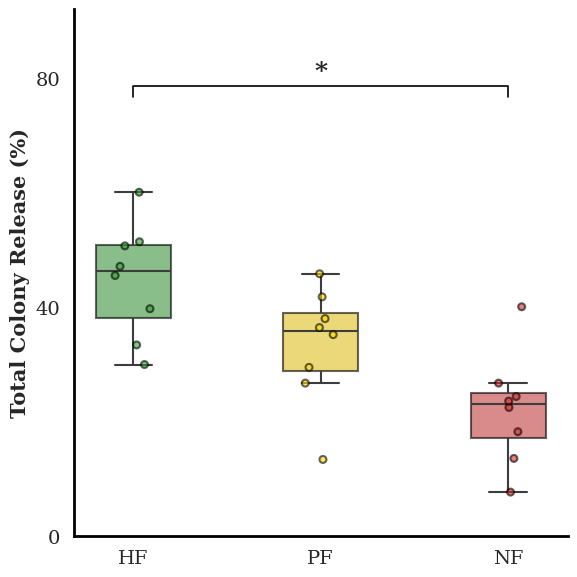

In [250]:
# --- BLOCK: PAIRED RELEASE DATA PLOT (PERCENTAGE) ---
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=global_fig_size)

# Updated Color Scheme & Strict Order
plot_colors = {'HF': '#2ca02c', 'PF': '#FFD700', 'NF': '#d62728'}
morph_order = ['HF', 'PF', 'NF']

# 1. Boxplot
ax = sns.boxplot(
    data=df_filtered,
    x='morph',
    y='% from total coloney',
    order=morph_order,
    palette=plot_colors,
    hue='morph',
    width=global_box_width,
    showfliers=False,
    linewidth=global_line_width,
    legend=False,
    boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor}
)

# 2. Stripplot
sns.stripplot(
    data=df_filtered,
    x='morph',
    y='% from total coloney',
    order=morph_order,
    hue='morph',
    palette=plot_colors,
    size=global_marker_size,
    jitter=global_jitter,
    alpha=global_alpha,
    zorder=5,
    legend=False,
    edgecolor=global_edgecolor,
    linewidth=global_line_width
)

# 3. Tiered Significance Brackets
y_max = df_filtered['% from total coloney'].max()
bracket_offsets = [y_max * 1.05, y_max * 1.18, y_max * 1.31]

# Map x-positions of the categories
x_coords = {'HF': 0, 'PF': 1, 'NF': 2}
bracket_pairs = [('HF', 'PF'), ('PF', 'NF'), ('HF', 'NF')]

for idx, (m1, m2) in enumerate(bracket_pairs):
    if (m1, m2) in pair_p_map:
        adj_p = pair_p_map[(m1, m2)]
        sig_symbol = get_significance_label(adj_p)

        # Skip drawing the bracket entirely if the result is not significant
        if sig_symbol == 'n.s.':
            continue

        x1, x2 = x_coords[m1], x_coords[m2]
        y_bar = bracket_offsets[idx]
        h_bracket = 2.0  # Height of the bracket down-ticks

        # Draw bracket horizontal line
        plt.plot([x1, x1, x2, x2], [y_bar - h_bracket, y_bar, y_bar, y_bar - h_bracket],
                 color='black', lw=1.2)
        # Draw significance asterisk label
        plt.text((x1 + x2) * 0.5, y_bar + 0.5, sig_symbol,
                 ha='center', va='bottom',
                 fontsize=global_asterisk_size,
                 fontweight=global_asterisk_weight)

# Final Layout Tweaks (No title, no X label, consistent Y label with parentheses and slash division)
plt.ylabel("Total Colony Release (%)")
plt.xlabel("")
ax.yaxis.set_major_locator(plt.MaxNLocator(global_y_nbins))
plt.ylim(0, 92)
sns.despine()

plt.tight_layout()
plt.savefig("Morph Release.svg", format="svg", dpi=600)
plt.show()

# GFP Intensity

## Block 1: Load Data & Outlier Removal
Loading Data and remoiving outliers using the 1.5 IQR method to ensure robust statistical analysis and visualization. This step is performed after initial data loading and filtering.


In [251]:
# Load your data
df = pd.read_csv('GFP_raw_sum_normalized.csv')
# Keep only HF and NF for analysis
df_gfp = df[df['Variant'].isin(['HF', 'NF'])].copy()
print("Data loaded successfully.")

# Calculate Q1 (25th percentile) and Q3 (75th percentile) for 'Intensity_per_µm2'
Q1 = df_gfp['Intensity_per_µm2'].quantile(0.25)
Q3 = df_gfp['Intensity_per_µm2'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out outliers
df_gfp_cleaned = df_gfp[(df_gfp['Intensity_per_µm2'] >= lower_bound) & (df_gfp['Intensity_per_µm2'] <= upper_bound)]

print(f"Original number of data points: {len(df_gfp)}")
print(f"Number of data points after outlier removal: {len(df_gfp_cleaned)}")

# Update df_gfp to the cleaned version for subsequent analysis
df_gfp = df_gfp_cleaned.copy()

print("Outliers removed and df_gfp updated.")

Data loaded successfully.
Original number of data points: 21
Number of data points after outlier removal: 21
Outliers removed and df_gfp updated.


## Block 2: Normality Check
It is standard practice to check if your data is normally distributed before choosing a statistical test.

In [252]:
hf_data = df_gfp[df_gfp['Variant'] == 'HF']['Intensity_per_µm2']
nf_data = df_gfp[df_gfp['Variant'] == 'NF']['Intensity_per_µm2']

# Shapiro-Wilk test
stat_hf, p_hf = stats.shapiro(hf_data)
stat_nf, p_nf = stats.shapiro(nf_data)

print(f"Normality Test - HF: p={p_hf:.4f}, NF: p={p_nf:.4f}")

Normality Test - HF: p=0.9369, NF: p=0.0738


## Block 3: Statistical Test
Based on the normality result, we Auto-select the appropriate test.

In [253]:
# Select test: T-test if normal (p > 0.05), Mann-Whitney if not (p < 0.05)
if p_hf < 0.05 or p_nf < 0.05:
    test_type = "Mann-Whitney U"
    stat, p_val = stats.mannwhitneyu(hf_data, nf_data)
else:
    test_type = "Independent T-test"
    stat, p_val = stats.ttest_ind(hf_data, nf_data)

print(f"Test used: {test_type}")
print(f"p-value: {p_val:.4e}")

Test used: Independent T-test
p-value: 1.1467e-08


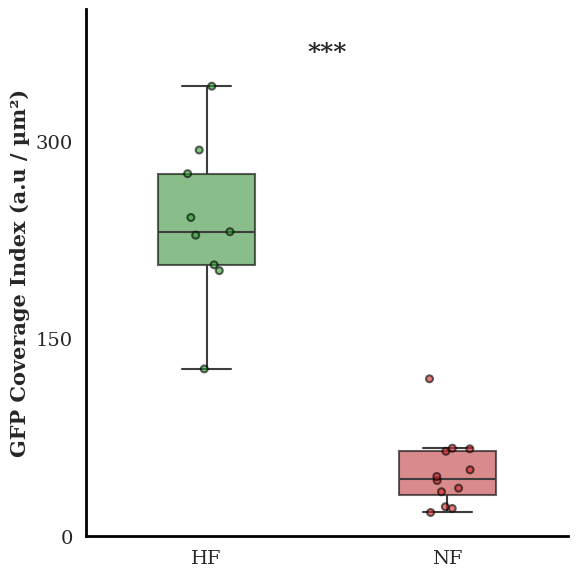

In [254]:
# --- BLOCK: GFP INTENSITY DATA PLOT ---
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Recalculate GFP significance locally to prevent global variable leakage
hf_gfp_vals = df_gfp[df_gfp['Variant'] == 'HF']['Intensity_per_µm2'].dropna()
nf_gfp_vals = df_gfp[df_gfp['Variant'] == 'NF']['Intensity_per_µm2'].dropna()
_, local_gfp_p = stats.ttest_ind(hf_gfp_vals, nf_gfp_vals, equal_var=True)

plt.figure(figsize=global_fig_size)

# 1. Boxplot
ax = sns.boxplot(
    data=df_gfp,
    x='Variant',
    y='Intensity_per_µm2',
    palette=variant_colors,
    hue='Variant',
    width=global_box_width,
    showfliers=False,
    linewidth=global_line_width,
    legend=False,
    boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor}
)

# 2. Stripplot
sns.stripplot(
    data=df_gfp,
    x='Variant',
    y='Intensity_per_µm2',
    hue='Variant',
    palette=variant_colors,
    size=global_marker_size,
    jitter=global_jitter,
    alpha=global_alpha,
    zorder=5,
    legend=False,
    edgecolor=global_edgecolor,
    linewidth=global_line_width
)

# 3. Dynamic Significance Marker using localized p-value
sig_label = get_significance_label(local_gfp_p)
if sig_label != 'n.s.':
    plt.text(0.5, df_gfp['Intensity_per_µm2'].max() * 1.05,
             sig_label,
             ha='center',
             va='bottom',
             fontsize=global_asterisk_size,
             fontweight=global_asterisk_weight)

# Final Touches (No title, no X label, consistent Y label with parentheses and slash division)
plt.ylabel("GFP Coverage Index (a.u / µm²)")
plt.xlabel("")
ax.yaxis.set_major_locator(plt.MaxNLocator(global_y_nbins))
plt.ylim(0, 400)
sns.despine()
plt.tight_layout()
plt.savefig("GFP_Intensity_Plot.svg", format="svg", dpi=600)
plt.show()

# Planulae Volume

## Block 1: Setup & Load 2026 Data
loads dataset, stripping any hidden spaces from the columns.

In [255]:

# 1. Load  Data
file = 'Planulae size.csv'
df = pd.read_csv(file, encoding='latin-1')
df.columns = df.columns.str.strip()


## Block 2: Geometric Filtering
Recalculate the dimensions from your ImageJ Area and Perimeter outputs to filter out any planulae that were imaged horizontally (Aspect Ratio < 2.5).

In [256]:
# 2. Geometric Filtering (Aspect Ratio >= 2.5)
A = df['area µm²']
P = df['perimeter µm']
r = (P - np.sqrt(P**2 - 4 * np.pi * A)) / (2 * np.pi)
w = 2 * r
L_total = ((P - 2 * np.pi * r) / 2) + (2 * r)
df['Aspect_Ratio'] = L_total / w

# Split data into removed vs good
df_removed_ratio = df[df['Aspect_Ratio'] < 2.5]
df_good = df[df['Aspect_Ratio'] >= 2.5].copy()

## Block 3: Remove 1.5 IQR Outliers
This sweeps the dataset to find any extreme volume measurements per morphotype (HF vs. NF).

In [257]:
import pandas as pd

# 3. Remove 1.5 IQR outliers per group
def remove_outliers(df, group_col, val_col):
    outliers_list = []
    clean_data_list = []

    for name, group in df.groupby(group_col):
        Q1 = group[val_col].quantile(0.25)
        Q3 = group[val_col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Filter rows
        outliers = group[(group[val_col] < lower_bound) | (group[val_col] > upper_bound)]
        clean = group[(group[val_col] >= lower_bound) & (group[val_col] <= upper_bound)]

        outliers_list.append(outliers)
        clean_data_list.append(clean)

    return pd.concat(clean_data_list), pd.concat(outliers_list)

# Apply filter specifically to Volume, renaming to df_planulae_clean
df_planulae_clean, df_planulae_outliers = remove_outliers(df_good, 'morph', 'Volume mm³')

# Print Data Removal Report
print(f"Total larvae ignored due to Aspect Ratio < 2.5: {len(df_removed_ratio)}")
if not df_removed_ratio.empty:
    print(df_removed_ratio[['no', 'morph', 'Label', 'Aspect_Ratio']])
print("-" * 40)

print(f"Total outliers removed (1.5 IQR) for Planulae Volume: {len(df_planulae_outliers)}")
if not df_planulae_outliers.empty:
    print(df_planulae_outliers[['no', 'morph', 'Label', 'Volume mm³']])
print("-" * 40)
print(f"Total larvae remaining for Planulae Volume analysis: {len(df_planulae_clean)}")

Total larvae ignored due to Aspect Ratio < 2.5: 4
      no morph  Label  Aspect_Ratio
50    51    HF      1      1.783012
81    82    HF     11      2.254283
94    95    NF      2      2.248411
101  102    NF      4      1.653646
----------------------------------------
Total outliers removed (1.5 IQR) for Planulae Volume: 9
      no morph  Label  Volume mm³
5      6    HF      2      0.4590
8      9    HF      1      0.4795
12    13    HF      2      0.4758
14    15    HF      2      0.4609
16    17    HF      2      0.1601
24    25    HF      3      0.1490
48    49    HF      5      0.5298
54    55    HF      5      0.4530
109  110    NF      2      0.4689
----------------------------------------
Total larvae remaining for Planulae Volume analysis: 125


## Block 4: Normality Test
Evaluates if the volume distribution of HF and NF cohorts follow a normal Gaussian curve using the Shapiro-Wilk test.

In [258]:
# 5. Normality Test & Diagnostic Plots
import matplotlib.ticker as ticker

unique_morphs = df_planulae_clean['morph'].unique()
print("NORMALITY TEST (Cleaned Data) ---")
normality_results = {}


for i, morph in enumerate(unique_morphs):
    data = df_planulae_clean[df_planulae_clean['morph'] == morph]['Volume mm³'].dropna()

    # Statistical Test
    shapiro_p = stats.shapiro(data)[1]
    is_normal = shapiro_p > 0.05
    normality_results[morph] = is_normal

    result = "Normal ✅" if is_normal else "NOT Normal ❌"
    print(f"Morph: {morph} (n={len(data)}) | Shapiro-Wilk p-value: {shapiro_p:.5f} | {result}")

NORMALITY TEST (Cleaned Data) ---
Morph: HF (n=82) | Shapiro-Wilk p-value: 0.96090 | Normal ✅
Morph: NF (n=43) | Shapiro-Wilk p-value: 0.66581 | Normal ✅


## 5. Statistical test based on normality & 7. Full statistical summary


In [259]:
# 5. Statistical test based on normality & 7. Full statistical summary
print("\n--- STATISTICAL COMPARISON SUMMARY ---")
morphs = list(normality_results.keys())

if len(morphs) == 2:
    group1 = df_planulae_clean[df_planulae_clean['morph'] == morphs[0]]['Volume mm³'].dropna()
    group2 = df_planulae_clean[df_planulae_clean['morph'] == morphs[1]]['Volume mm³'].dropna()

    # Logic gate for stats
    if all(normality_results.values()):
        print("Verdict: Both groups are normally distributed.")
        stat, p_val = stats.ttest_ind(group1, group2)
        test_used = "Independent T-test"
    else:
        print("Verdict: Non-normal distribution detected.")
        stat, p_val = stats.mannwhitneyu(group1, group2)
        test_used = "Mann-Whitney U"

    significance = "Significant ⭐" if p_val < 0.05 else "Not Significant (NS)"

    # 7. Summary
    print(f"\nComparison: {morphs[0]} vs {morphs[1]}")
    print(f"Test Used: {test_used}")
    print(f"Statistic: {stat:.5f}")
    print(f"p-value: {p_val:.5e} | {significance}")
else:
    print("More than 2 morphs detected. Code requires adjustment for ANOVA/Kruskal-Wallis.")


--- STATISTICAL COMPARISON SUMMARY ---
Verdict: Both groups are normally distributed.

Comparison: HF vs NF
Test Used: Independent T-test
Statistic: 3.00522
p-value: 3.21720e-03 | Significant ⭐


## Block 8: Global Style Plotting
Creates a publication-ready figure Boxplot with jittered dots to show the exact spread of HF vs. NF volume.

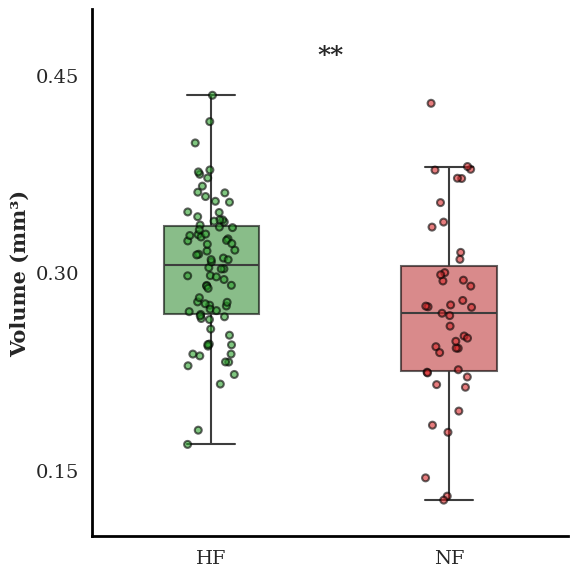

In [260]:
# --- BLOCK: PLANULAE VOLUME DATA PLOT ---
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
from scipy import stats

# Recalculate Volume significance locally to prevent global variable leakage
hf_vol_vals = df_planulae_clean[df_planulae_clean['morph'] == 'HF']['Volume mm³'].dropna()
nf_vol_vals = df_planulae_clean[df_planulae_clean['morph'] == 'NF']['Volume mm³'].dropna()
_, local_vol_p = stats.ttest_ind(hf_vol_vals, nf_vol_vals, equal_var=True)

fig, ax_box = plt.subplots(figsize=global_fig_size)
plot_order = [m for m in ['HF', 'NF'] if m in df_planulae_clean['morph'].unique()]

# Main comparison plot
sns.boxplot(
    data=df_planulae_clean,
    x='morph',
    y='Volume mm³',
    order=plot_order,
    hue='morph',
    palette=variant_colors,
    ax=ax_box,
    showfliers=False,
    legend=False,
    width=global_box_width,
    boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor},
    linewidth=global_line_width
)

# Jittered points
sns.stripplot(
    data=df_planulae_clean,
    x='morph',
    y='Volume mm³',
    order=plot_order,
    hue='morph',
    palette=variant_colors,
    alpha=global_alpha,
    jitter=global_jitter,
    size=global_marker_size,
    ax=ax_box,
    legend=False,
    linewidth=global_line_width,
    edgecolor=global_edgecolor
)

# --- SIGNIFICANCE ANNOTATION ---
sig_str = get_significance_label(local_vol_p)
if sig_str != 'n.s.':
    x1, x2 = 0, 1
    y_max = df_planulae_clean['Volume mm³'].max()
    h_ast = y_max * 1.05
    ax_box.text((x1+x2)*.5, h_ast, sig_str,
                ha='center', va='bottom',
                fontsize=global_asterisk_size,
                fontweight=global_asterisk_weight)

# Labels and Ticks (No title, no X label, consistent Y label with parentheses)
ax_box.set_ylabel("Volume (mm³)")
ax_box.set_xlabel("")
ax_box.set_ylim(0.1, 0.5)
ax_box.yaxis.set_major_locator(ticker.MaxNLocator(nbins=global_y_nbins))

sns.despine()
plt.tight_layout()
plt.savefig("Planulae_Volume_Plot.svg", format="svg", dpi=600)
plt.show()

# Respiration Rate

## Block 1: Loading Data and combining expirimantal loadout with Oxygen raw data

In [261]:
import pandas as pd
import numpy as np
from scipy.stats import linregress

# 1. Load data files securely using the Latin1 text layout decoder
df_oxy = pd.read_csv('Respiration.csv', encoding='latin1')
df_load = pd.read_csv('loadout.csv', encoding='latin1')

# 2. Convert the 2D loadout grid template into a flat coordinate map
df_load = df_load.set_index('Unnamed: 0')
well_morph_lookup = {}

for row_letter in df_load.index:
    for col_number in ['1', '2', '3', '4', '5', '6']:
        well_coordinate = f"{row_letter}{col_number}"
        morphtype = df_load.loc[row_letter, col_number]
        well_morph_lookup[well_coordinate] = morphtype

# 3. Target all possible well channels across the 24-well configuration plate
target_channels = [f"{r}{c}" for r in ['A', 'B', 'C', 'D'] for c in range(1, 7)]
compiled_dataset = []

# 4. Loop through each target channel, isolate values, and process active rates
for channel in target_channels:
    if channel in df_oxy.columns:
        # Isolate the targeted timeline slice and scrub empty cells
        data_slice = df_oxy[['Time/Min.', channel]].dropna()

        # Enforce strict float properties to block text parsing anomalies
        time_data = pd.to_numeric(data_slice['Time/Min.'], errors='coerce')
        oxy_data = pd.to_numeric(data_slice[channel], errors='coerce')

        # Clean out any remaining missing values after conversion
        valid_indices = time_data.notna() & oxy_data.notna()
        time_clean = time_data[valid_indices]
        oxy_clean = oxy_data[valid_indices]

        if len(time_clean) > 1:
            # Perform ordinary least squares regression
            slope, intercept, r_value, p_value, std_err = linregress(time_clean, oxy_clean)

            # Append rows, inverting the rate slope parameter into consumption speed
            compiled_dataset.append({
                'Well': channel,
                'Morph': well_morph_lookup.get(channel, 'Unknown'),
                'Respiration_Rate_umol_L_min': -slope,
                'R_Squared': r_value ** 2
            })

# 5. Build the clean, long-format final dataframe structure
df_planula_respiration = pd.DataFrame(compiled_dataset)

# 6. Display primary processing metrics directly inside the workspace window
print("--- FIRST 10 INTEGRATED SAMPLES ---")
print(df_planula_respiration.head(10).to_string(index=False))

print("\n--- GLOBAL AGGREGATED SUMMARY LOGS ---")
summary = df_planula_respiration.groupby('Morph')['Respiration_Rate_umol_L_min'].agg(['count', 'mean', 'std', 'min', 'max'])
print(summary)

# 7. Export the final long-format output structure to your workspace directory
df_planula_respiration.to_csv('Planula_Baseline_Respiration_Processed.csv', index=False)

--- FIRST 10 INTEGRATED SAMPLES ---
Well Morph  Respiration_Rate_umol_L_min  R_Squared
  A1    HF                     0.404921   0.958150
  A2    HF                     1.013406   0.976984
  A3    HF                     1.144284   0.986136
  A4    NF                     1.598505   0.982093
  A5    NF                     1.862354   0.973296
  A6 blank                    -0.023313   0.389262
  B1    HF                     1.188499   0.966387
  B2    HF                     1.474413   0.980757
  B3    HF                     1.518870   0.978700
  B4    NF                     1.798730   0.991471

--- GLOBAL AGGREGATED SUMMARY LOGS ---
       count      mean       std       min       max
Morph                                               
HF        10  1.501288  0.804601  0.404921  3.142877
NF        10  1.636851  0.596712  0.727637  2.936219
blank      4  0.002226  0.044015 -0.023313  0.067945


## Block 2: Substracting Avarge Blank From all Samples


In [262]:
import pandas as pd
from scipy import stats

# 1. Calculate the mean respiration rate of the blanks
blank_avg = df_planula_respiration[df_planula_respiration['Morph'] == 'blank']['Respiration_Rate_umol_L_min'].mean()
print(f"Average Blank Respiration Rate (Baseline): {blank_avg:.6f} umol/L/min")

# 2. Conversion factor to absolute molar amount:
# PreSens 24-well microplate volume = 80 uL = 0.080 mL = 8e-5 L
# umol/L * (8e-5 L) * (1000 nmol / 1 umol) = 0.080 nmol O2 in the well
WELL_VOLUME_ML = 0.080
LARVAE_PER_WELL = 3

# Un-normalized rate per individual planula (nmol O2 / planula / min)
df_planula_respiration['Respiration_Rate_nmol_per_Planula'] = (
    (df_planula_respiration['Respiration_Rate_umol_L_min'] - blank_avg) * WELL_VOLUME_ML / LARVAE_PER_WELL
)

# Keep the concentration rate column for reference
df_planula_respiration['Corrected_Respiration_Rate_per_Planula'] = (
    (df_planula_respiration['Respiration_Rate_umol_L_min'] - blank_avg) / LARVAE_PER_WELL
)

# 3. Filter to keep only experimental samples (removing blanks)
df_respiration_corrected = df_planula_respiration[df_planula_respiration['Morph'] != 'blank'].copy()

# 4. Display un-normalized per-planula summary and stats (All 10 wells)
print("\n--- UN-NORMALIZED RATE PER PLANULA (nmol O2 / planula / min) ---")
summary_per_planula = df_respiration_corrected.groupby('Morph')['Respiration_Rate_nmol_per_Planula'].agg(['count', 'mean', 'std', 'min', 'max'])
display(summary_per_planula)

# Per-larva statistics across all 10 wells
hf_larva = df_respiration_corrected[df_respiration_corrected['Morph'] == 'HF']['Respiration_Rate_nmol_per_Planula']
nf_larva = df_respiration_corrected[df_respiration_corrected['Morph'] == 'NF']['Respiration_Rate_nmol_per_Planula']
t_larva, p_t_larva = stats.ttest_ind(hf_larva, nf_larva)
u_larva, p_u_larva = stats.mannwhitneyu(hf_larva, nf_larva)
print(f"Un-normalized t-test: p = {p_t_larva:.4f} | Mann-Whitney U: p = {p_u_larva:.4f}")

# 5. Export corrected dataset
df_respiration_corrected.to_csv('Planula_Respiration_Corrected.csv', index=False)

Average Blank Respiration Rate (Baseline): 0.002226 umol/L/min

--- UN-NORMALIZED RATE PER PLANULA (nmol O2 / planula / min) ---


,count,mean,std,min,max
Morph,,,,,
HF,10,0.039975,0.021456,0.010739,0.083751
NF,10,0.043590,0.015912,0.019344,0.078240


Un-normalized t-test: p = 0.6738 | Mann-Whitney U: p = 0.3447


## Block 3: Normelizing Raspiration Rate by Volume

In [263]:
# --- BLOCK: VOLUME-SPECIFIC RESPIRATION NORMALIZATION ---

# 1. Calculate average volume per morph from the cleaned volume data
avg_volume = df_planulae_clean.groupby('morph')['Volume mm³'].mean()
print("Average Volume per Morph (mm³):")
print(avg_volume)

# 2. Map volumes to respiration dataframe and normalize (nmol O2 / mm3 / min)
df_respiration_corrected['Avg_Morph_Volume_mm3'] = df_respiration_corrected['Morph'].map(avg_volume)
df_respiration_corrected['Respiration_Rate_per_mm3'] = (
    df_respiration_corrected['Respiration_Rate_nmol_per_Planula'] / df_respiration_corrected['Avg_Morph_Volume_mm3']
)

# 3. Display updated summary across all 10 wells
print("\n--- SUMMARY: VOLUME-NORMALIZED RESPIRATION RATE (nmol O2 / mm3 / min) ---")
vol_summary = df_respiration_corrected.groupby('Morph')['Respiration_Rate_per_mm3'].agg(['count', 'mean', 'std'])
display(vol_summary)

# Unpruned volume-normalized comparison
hf_vol_all = df_respiration_corrected[df_respiration_corrected['Morph'] == 'HF']['Respiration_Rate_per_mm3']
nf_vol_all = df_respiration_corrected[df_respiration_corrected['Morph'] == 'NF']['Respiration_Rate_per_mm3']
t_all, p_t_all = stats.ttest_ind(hf_vol_all, nf_vol_all)
print(f"All 10 wells volume-normalized t-test: p = {p_t_all:.4f}")
vol_summary = df_respiration_corrected.groupby('Morph')['Respiration_Rate_per_mm3'].agg(['count', 'mean', 'std'])
display(vol_summary)

Average Volume per Morph (mm³):
morph
HF    0.302380
NF    0.269826
Name: Volume mm³, dtype: float64

--- SUMMARY: VOLUME-NORMALIZED RESPIRATION RATE (nmol O2 / mm3 / min) ---


,count,mean,std
Morph,,,
HF,10,0.132201,0.070957
NF,10,0.161549,0.058973


All 10 wells volume-normalized t-test: p = 0.3278


,count,mean,std
Morph,,,
HF,10,0.132201,0.070957
NF,10,0.161549,0.058973


## Block 4: Removing Outliers X1.5IQR


In [264]:
def remove_respiration_outliers(df, group_col, val_col):
    clean_list = []
    outlier_list = []
    for name, group in df.groupby(group_col):
        Q1 = group[val_col].quantile(0.25)
        Q3 = group[val_col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = group[(group[val_col] < lower) | (group[val_col] > upper)]
        clean = group[(group[val_col] >= lower) & (group[val_col] <= upper)]

        clean_list.append(clean)
        outlier_list.append(outliers)
    return pd.concat(clean_list), pd.concat(outlier_list)

# Apply to volume-specific respiration rate
df_resp_final, df_resp_outliers = remove_respiration_outliers(df_respiration_corrected, 'Morph', 'Respiration_Rate_per_mm3')

print("--- RESPIRATION OUTLIER REPORT ---")
print(f"Outliers removed: {len(df_resp_outliers)}")
if not df_resp_outliers.empty:
    display(df_resp_outliers[['Well', 'Morph', 'Respiration_Rate_per_mm3']])
print(f"Samples remaining: {len(df_resp_final)}")

--- RESPIRATION OUTLIER REPORT ---
Outliers removed: 4


,Well,Morph,Respiration_Rate_per_mm3
0,A1,HF,0.035513
12,C1,HF,0.276971
13,C2,HF,0.233059
14,C3,NF,0.289964


Samples remaining: 16


## Block 5: Normality check


In [265]:
# --- BLOCK: NORMALITY TEST FOR CLEANED RESPIRATION ---

# 1. Isolate the final cleaned groups
hf_final_vals = df_resp_final[df_resp_final['Morph'] == 'HF']['Respiration_Rate_per_mm3']
nf_final_vals = df_resp_final[df_resp_final['Morph'] == 'NF']['Respiration_Rate_per_mm3']

# 2. Shapiro-Wilk Test
stat_hf_f, p_hf_final = stats.shapiro(hf_final_vals)
stat_nf_f, p_nf_final = stats.shapiro(nf_final_vals)

print(f"--- FINAL NORMALITY TEST (n={len(df_resp_final)}) ---")
print(f"HF Morph (n={len(hf_final_vals)}): p = {p_hf_final:.4f} {'(Normal)' if p_hf_final > 0.05 else '(NOT Normal)'}")
print(f"NF Morph (n={len(nf_final_vals)}): p = {p_nf_final:.4f} {'(Normal)' if p_nf_final > 0.05 else '(NOT Normal)'}")

--- FINAL NORMALITY TEST (n=16) ---
HF Morph (n=7): p = 0.5082 (Normal)
NF Morph (n=9): p = 0.2786 (Normal)


## Block 6: Plotting

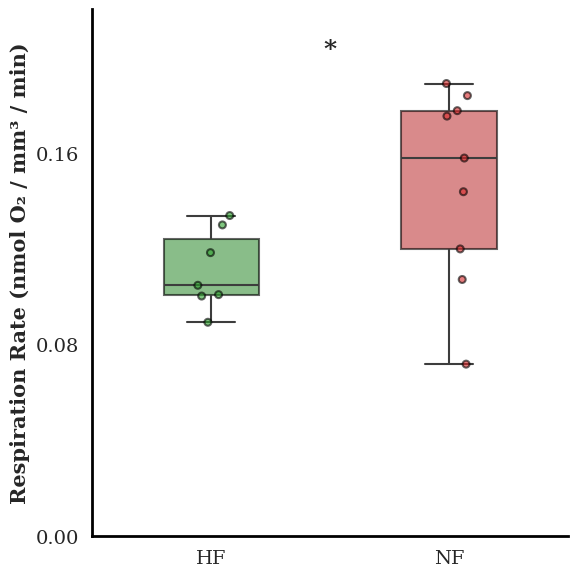

In [266]:
# --- BLOCK: RESPIRATION RATE PLOT ---
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Recalculate Respiration significance locally to prevent global variable leakage
hf_resp_vals = df_resp_final[df_resp_final['Morph'] == 'HF']['Respiration_Rate_per_mm3'].dropna()
nf_resp_vals = df_resp_final[df_resp_final['Morph'] == 'NF']['Respiration_Rate_per_mm3'].dropna()
_, local_resp_p = stats.ttest_ind(hf_resp_vals, nf_resp_vals, equal_var=True)

plt.figure(figsize=global_fig_size)

# Boxplot
ax = sns.boxplot(
    data=df_resp_final,
    x='Morph',
    y='Respiration_Rate_per_mm3',
    palette=variant_colors,
    hue='Morph',
    width=global_box_width,
    showfliers=False,
    linewidth=global_line_width,
    legend=False,
    boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor}
)

# Stripplot
sns.stripplot(
    data=df_resp_final,
    x='Morph',
    y='Respiration_Rate_per_mm3',
    hue='Morph',
    palette=variant_colors,
    size=global_marker_size,
    jitter=global_jitter,
    alpha=global_alpha,
    zorder=5,
    legend=False,
    edgecolor=global_edgecolor,
    linewidth=global_line_width
)

# Significance Label
sig_label = get_significance_label(local_resp_p)
if sig_label != 'n.s.':
    y_max = df_resp_final['Respiration_Rate_per_mm3'].max()
    plt.text(0.5, y_max * 1.05,
             sig_label,
             ha='center', va='bottom',
             fontsize=global_asterisk_size,
             fontweight=global_asterisk_weight)

# Final Touches (No title, no X label, consistent Y label with parentheses and slash divisions)
plt.ylabel("Respiration Rate (nmol O₂ / mm³ / min)")
plt.xlabel("")
ax.yaxis.set_major_locator(plt.MaxNLocator(global_y_nbins))
plt.ylim(0, 0.22)
sns.despine()

plt.tight_layout()
plt.savefig("Respiration_Rate_Final_Cleaned.svg", format="svg", dpi=600)
plt.show()

# Larval Protein Density

## Block 1: Load Protein Data & Merge with Volume
We will load the protein concentration data ($μg/ml$) and associate it with the average morph volumes calculated in the previous 'Planulae Volume' section.

In [267]:
import pandas as pd

# 1. Load protein data
df_prot = pd.read_csv('Protein.csv', encoding='latin1')

# 2. Cleanup: Strip whitespace and drop empty rows
df_prot.columns = df_prot.columns.str.strip()
print(f"Detected columns: {df_prot.columns.tolist()}")

df_prot = df_prot.dropna(subset=['morph']).copy()
df_prot['morph'] = df_prot['morph'].str.strip()

# --- Show number of samples loaded ---
print(f"Total valid samples loaded: {len(df_prot)}")
print(df_prot.groupby('morph').size())

# 3. Map average volumes from the Planulae Volume section
df_prot['Avg_Volume_mm3'] = df_prot['morph'].map(avg_volume)

# 4. Recalculate protein density using absolute protein per larva divided by individual morph volume
# FIX: Using 'con per planulae ug/ml' which is the correct column in your CSV
df_prot['Protein_Density_ug_mm3'] = df_prot['con per planulae ug/ml'] / df_prot['Avg_Volume_mm3']

print("\n--- Average Volumes Used for Calculation (mm3) ---")
display(avg_volume)

print("\n--- PROTEIN DATA PREVIEW ---")
display(df_prot[['sample id', 'morph', 'con per planulae ug/ml', 'Protein_Density_ug_mm3']].head())

print("\n--- PROTEIN DENSITY SUMMARY (Initial) ---")
prot_summary = df_prot.groupby('morph')['Protein_Density_ug_mm3'].agg(['count', 'mean', 'std'])
display(prot_summary)

Detected columns: ['sample id', 'morph', 'OD1', 'OD2', 'OD3', 'ave OD', 'ug/ml', 'no of planulae', 'con per planulae ug/ml', 'avarage vol', 'prot ug/mm3']
Total valid samples loaded: 19
morph
HF    10
NF     9
dtype: int64

--- Average Volumes Used for Calculation (mm3) ---


,Volume mm³
morph,
HF,0.302380
NF,0.269826



--- PROTEIN DATA PREVIEW ---


,sample id,morph,con per planulae ug/ml,Protein_Density_ug_mm3
0,600,HF,21.146986,69.935021
1,601,HF,14.164119,46.842042
2,602,HF,14.180176,46.895141
3,603,HF,20.076215,66.393885
4,604,HF,19.770413,65.382568



--- PROTEIN DENSITY SUMMARY (Initial) ---


,count,mean,std
morph,,,
HF,10,64.609425,10.375863
NF,9,61.611067,10.939784


## Block 2: Outlier Removal
Applying the 1.5 IQR method to ensure the protein density comparison is robust.

In [268]:
# --- BLOCK 2: UPDATED OUTLIER REMOVAL ---
def remove_prot_outliers(df, group_col, val_col):
    clean_list = []
    outlier_list = []
    print("--- OUTLIER CALCULATION LOGIC (1.5 IQR Rule) ---")

    df_subset = df.dropna(subset=[val_col, group_col])
    for name, group in df_subset.groupby(group_col):
        Q1 = group[val_col].quantile(0.25)
        Q3 = group[val_col].quantile(0.75)
        IQR = Q3 - Q1
        lower_fence = Q1 - 1.5 * IQR
        upper_fence = Q3 + 1.5 * IQR

        print(f"\nMorph: {name}")
        print(f"  - Lower Fence: {lower_fence:.2f}, Upper Fence: {upper_fence:.2f}")

        clean = group[(group[val_col] >= lower_fence) & (group[val_col] <= upper_fence)]
        outliers = group[(group[val_col] < lower_fence) | (group[val_col] > upper_fence)]

        clean_list.append(clean)
        outlier_list.append(outliers)

    return pd.concat(clean_list), pd.concat(outlier_list)

df_prot_clean, df_prot_removed = remove_prot_outliers(df_prot, 'morph', 'Protein_Density_ug_mm3')

# --- Formatting: Use 'sample id' instead of missing 'vile no' ---
df_prot_clean['sample id'] = df_prot_clean['sample id'].astype(int)
df_prot_clean = df_prot_clean.sort_values('sample id').set_index('sample id', drop=False)

if not df_prot_removed.empty:
    df_prot_removed['sample id'] = df_prot_removed['sample id'].astype(int)
    df_prot_removed = df_prot_removed.sort_values('sample id').set_index('sample id', drop=False)

print("\n--- PROTEIN OUTLIER SUMMARY ---")
print(f"Samples remaining: {len(df_prot_clean)}")
if not df_prot_removed.empty:
    # Using 'con per planulae ug/ml' to match your actual column names
    display(df_prot_removed[['sample id', 'morph', 'con per planulae ug/ml', 'Protein_Density_ug_mm3']])

print("\n--- FULL CLEANED DATAFRAME ---")
display(df_prot_clean[['sample id', 'morph', 'con per planulae ug/ml', 'Protein_Density_ug_mm3']])

--- OUTLIER CALCULATION LOGIC (1.5 IQR Rule) ---

Morph: HF
  - Lower Fence: 50.40, Upper Fence: 81.53

Morph: NF
  - Lower Fence: 37.81, Upper Fence: 90.73

--- PROTEIN OUTLIER SUMMARY ---
Samples remaining: 17


,sample id,morph,con per planulae ug/ml,Protein_Density_ug_mm3
sample id,,,,
601,601,HF,14.164119,46.842042
602,602,HF,14.180176,46.895141



--- FULL CLEANED DATAFRAME ---


,sample id,morph,con per planulae ug/ml,Protein_Density_ug_mm3
sample id,,,,
600,600,HF,21.146986,69.935021
603,603,HF,20.076215,66.393885
604,604,HF,19.770413,65.382568
605,605,HF,20.681355,68.395136
606,606,HF,22.580929,74.677203
607,607,HF,18.435882,60.969151
608,608,HF,23.281058,76.992593
609,609,HF,21.049162,69.611509
610,610,NF,19.590543,72.604470


## Block 3: Normality Check
We evaluate the distribution of the cleaned protein density data for both HF and NF groups to determine the appropriate statistical test.

In [269]:
# --- BLOCK 3: UPDATED NORMALITY TEST ---
hf_prot = df_prot_clean[df_prot_clean['morph'] == 'HF']['Protein_Density_ug_mm3']
nf_prot = df_prot_clean[df_prot_clean['morph'] == 'NF']['Protein_Density_ug_mm3']

stat_hf, p_hf = stats.shapiro(hf_prot)
stat_nf, p_nf = stats.shapiro(nf_prot)

print(f"--- PROTEIN DENSITY NORMALITY TEST (Corrected Logic) ---")
print(f"HF Morph (n={len(hf_prot)}): p = {p_hf:.4f}")
print(f"NF Morph (n={len(nf_prot)}): p = {p_nf:.4f}")

--- PROTEIN DENSITY NORMALITY TEST (Corrected Logic) ---
HF Morph (n=8): p = 0.9339
NF Morph (n=9): p = 0.3551


## Block 4: Statistical Comparison & Visualization
Based on the normality results, we perform the final comparison and generate the figure.

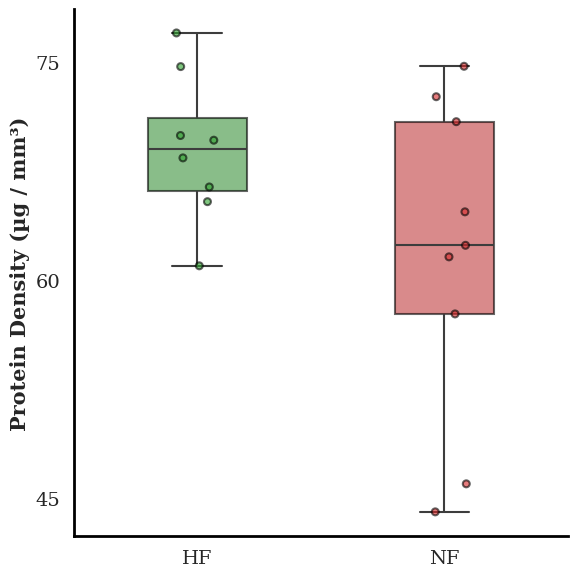

In [270]:
# --- BLOCK: PROTEIN DENSITY DATA PLOT ---
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Recalculate protein density p-value locally to prevent global variable leakage
hf_prot_vals = df_prot_clean[df_prot_clean['morph'] == 'HF']['Protein_Density_ug_mm3'].dropna()
nf_prot_vals = df_prot_clean[df_prot_clean['morph'] == 'NF']['Protein_Density_ug_mm3'].dropna()
_, local_p_val = stats.ttest_ind(hf_prot_vals, nf_prot_vals, equal_var=True)

plt.figure(figsize=global_fig_size)
plot_order = ['HF', 'NF']

# Boxplot
ax = sns.boxplot(
    data=df_prot_clean,
    x='morph',
    y='Protein_Density_ug_mm3',
    order=plot_order,
    palette=variant_colors,
    hue='morph',
    width=global_box_width,
    showfliers=False,
    linewidth=global_line_width,
    legend=False,
    boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor}
)

# Stripplot
sns.stripplot(
    data=df_prot_clean,
    x='morph',
    y='Protein_Density_ug_mm3',
    order=plot_order,
    hue='morph',
    palette=variant_colors,
    size=global_marker_size,
    jitter=global_jitter,
    alpha=global_alpha,
    zorder=5,
    legend=False,
    edgecolor=global_edgecolor,
    linewidth=global_line_width
)

# Dynamic Significance Marker using local_p_val instead of global p_val
sig_label = get_significance_label(local_p_val)
if sig_label != 'n.s.':
    y_max = df_prot_clean['Protein_Density_ug_mm3'].max()
    plt.text(0.5, y_max * 1.05,
             sig_label,
             ha='center', va='bottom',
             fontsize=global_asterisk_size,
             fontweight=global_asterisk_weight)

# Labels and styling tweaks (No title, no X label, consistent Y label with parentheses and slash divisions)
plt.ylabel("Protein Density (µg / mm³)")
plt.xlabel("")
ax.yaxis.set_major_locator(plt.MaxNLocator(global_y_nbins))
sns.despine()
plt.tight_layout()
plt.savefig("Larval_Protein_Density_Corrected.svg", format="svg", dpi=600)
plt.show()

# Symbionts Cell Count

## Block 1&2: Load Data & Convert Metrics (Cell/Planula + Cell/Volume)
This block loads the CSV, handles the spelling of your columns, and performs the mathematical normalizations. Note: I added an EXTRACTION_VOL_ML variable. If you crushed your planulae in 1 mL of seawater/preservative, leave it as 1.0. If you used 500 µL, change it to 0.5.

In [271]:
# --- BLOCK 1 & 2: LOAD DATA & TECHNICAL QC (GRID CLUMPING) ---
import pandas as pd
import numpy as np

# Load Data
filename = 'Algae_cell_count.csv'
df_algae_data = pd.read_csv(filename)
df_algae_data.columns = df_algae_data.columns.str.strip() # Clean hidden spaces

# Focus only on HF and NF morphs
df_algae_data = df_algae_data[df_algae_data['morph'].isin(['HF', 'NF'])].copy()

print("--- TIER 1: TECHNICAL QC REPORT (GRID CLUMPING) ---")
# Explicitly grab ONLY the grid count columns to prevent re-execution memory bugs
valid_count_cols = [c for c in df_algae_data.columns if c == 'Counts...' or 'Unnamed' in c]
count_data = df_algae_data[valid_count_cols].apply(pd.to_numeric, errors='coerce')

clean_means = []
grids_dropped = []

# Iterate through every sample (row)
for idx, row in count_data.iterrows():
    # Extract only valid numbers, drop empty columns
    grids = row.dropna()

    # If a sample has at least 4 grid counts, we can perform IQR
    if len(grids) >= 4:
        Q1 = np.percentile(grids, 25)
        Q3 = np.percentile(grids, 75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        # Filter the grids for this specific sample
        clean_grids = grids[(grids >= lower) & (grids <= upper)]
        clean_means.append(clean_grids.mean())
        grids_dropped.append(len(grids) - len(clean_grids))
    else:
        # Not enough grids to do IQR reliably, just take the mean
        clean_means.append(grids.mean())
        grids_dropped.append(0)

df_algae_data['Clean_Grid_Mean'] = clean_means
df_algae_data['Clumps_Dropped'] = grids_dropped

print(f"Total Technical Clumps (Grids) Dropped across all samples: {sum(grids_dropped)}")
# Show samples where grids were heavily manipulated
highly_cleaned = df_algae_data[df_algae_data['Clumps_Dropped'] > 0]
if not highly_cleaned.empty:
    print("\nSamples requiring grid cleanup:")
    print(highly_cleaned[['Sample No', 'morph', 'Average', 'Clean_Grid_Mean', 'Clumps_Dropped']])

--- TIER 1: TECHNICAL QC REPORT (GRID CLUMPING) ---
Total Technical Clumps (Grids) Dropped across all samples: 4

Samples requiring grid cleanup:
    Sample No morph  Average  Clean_Grid_Mean  Clumps_Dropped
4         604    HF   2.0000         2.500000               1
6         606    HF  45.7143        39.833333               1
7         607    HF  16.6667        18.200000               1
18        620    NF  37.3750        34.714286               1


## Block 3: Biological Outlier Removal & Density Calculations
Replace your existing Block 3 cell with this code:

In [272]:
# --- BLOCK 3: RECALCULATE DENSITIES BASED ON CLEAN MEANS ---
# Standard Hemocytometer formula: Count x 10,000
df_algae_data['Clean_Conc_Cells_mL'] = df_algae_data['Clean_Grid_Mean'] * 10000

# Fix: Set to exact 500 uL volume given in methods
EXTRACTION_VOL_ML = 0.5
df_algae_data['Cells_per_Planula'] = (df_algae_data['Clean_Conc_Cells_mL'] * EXTRACTION_VOL_ML) / df_algae_data['no of plaunlae per vile']

volume_map = {'HF': 0.3024, 'NF': 0.2698}
df_algae_data['Volume_mm3'] = df_algae_data['morph'].map(volume_map)
df_algae_data['Cells_per_mm3'] = df_algae_data['Cells_per_Planula'] / df_algae_data['Volume_mm3']

df_algae_data = df_algae_data.dropna(subset=['Cells_per_mm3']).copy()

# --- TIER 2: BIOLOGICAL OUTLIER REMOVAL (PER MORPH) ---
print("\n--- TIER 2: BIOLOGICAL QC REPORT (POPULATION DENSITY) ---")
def remove_biological_outliers(data, group_col, val_col):
    outliers_list, clean_list = [], []
    for name, group in data.groupby(group_col):
        Q1, Q3 = group[val_col].quantile(0.25), group[val_col].quantile(0.75)
        IQR = Q3 - Q1
        lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

        outliers = group[(group[val_col] < lower) | (group[val_col] > upper)]
        clean = group[(group[val_col] >= lower) & (group[val_col] <= upper)]

        outliers_list.append(outliers)
        clean_list.append(clean)
    return pd.concat(clean_list), pd.concat(outliers_list)

df_symbiont_clean, df_symbiont_outliers = remove_biological_outliers(df_algae_data, 'morph', 'Cells_per_mm3')

print(f"Total Biological Outliers Removed: {len(df_symbiont_outliers)}")
if not df_symbiont_outliers.empty:
    print(df_symbiont_outliers[['Sample No', 'morph', 'Cells_per_mm3']])
print(f"Total Samples Remaining for Final Stats: {len(df_symbiont_clean)}")


--- TIER 2: BIOLOGICAL QC REPORT (POPULATION DENSITY) ---
Total Biological Outliers Removed: 0
Total Samples Remaining for Final Stats: 19


## Block 4 & 5: Normality Check & Automated Stats
This block evaluates both metrics (Cells_per_Planula and Cells_per_mm3), decides between a T-test or Mann-Whitney U based on normality, and prints a formatted statistical report.

In [273]:
# 4. Normality Test & 5. Auto Statistical Test
from scipy import stats

metrics_to_test = ['Cells_per_Planula', 'Cells_per_mm3']
morphs = df_symbiont_clean['morph'].unique()

print("\n" + "="*45)
print(" 🔬 COMPREHENSIVE STATISTICAL REPORT ")
print("="*45)

for metric in metrics_to_test:
    print(f"\n➤ Analyzing: {metric}")
    print("-" * 45)

    normality_pass = True
    groups = []

    # Check Normality
    for morph in morphs:
        data = df_symbiont_clean[df_symbiont_clean['morph'] == morph][metric].dropna()
        groups.append(data)
        stat, p_shapiro = stats.shapiro(data)
        is_normal = p_shapiro > 0.05
        normality_pass = normality_pass and is_normal
        print(f"[{morph}] Normality (p={p_shapiro:.4f}) -> {'Normal ✅' if is_normal else 'NOT Normal ❌'}")

    # Run Automated Stats
    if len(groups) == 2:
        if normality_pass:
            stat, p_val = stats.ttest_ind(groups[0], groups[1], equal_var=False)
            test_used = "Welch's T-test"
        else:
            stat, p_val = stats.mannwhitneyu(groups[0], groups[1], alternative='two-sided')
            test_used = "Mann-Whitney U Test"

        sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "n.s."

        print(f"Test Used : {test_used}")
        print(f"P-Value   : {p_val:.5e} | {sig}")
        print(f"Mean HF   : {groups[0].mean():.2e}")
        print(f"Mean NF   : {groups[1].mean():.2e}")
print("="*45)


 🔬 COMPREHENSIVE STATISTICAL REPORT 

➤ Analyzing: Cells_per_Planula
---------------------------------------------
[HF] Normality (p=0.0059) -> NOT Normal ❌
[NF] Normality (p=0.1060) -> Normal ✅
Test Used : Mann-Whitney U Test
P-Value   : 3.91267e-01 | n.s.
Mean HF   : 3.64e+04
Mean NF   : 3.73e+04

➤ Analyzing: Cells_per_mm3
---------------------------------------------
[HF] Normality (p=0.0059) -> NOT Normal ❌
[NF] Normality (p=0.1060) -> Normal ✅
Test Used : Mann-Whitney U Test
P-Value   : 2.05667e-01 | n.s.
Mean HF   : 1.20e+05
Mean NF   : 1.38e+05


## Plotting

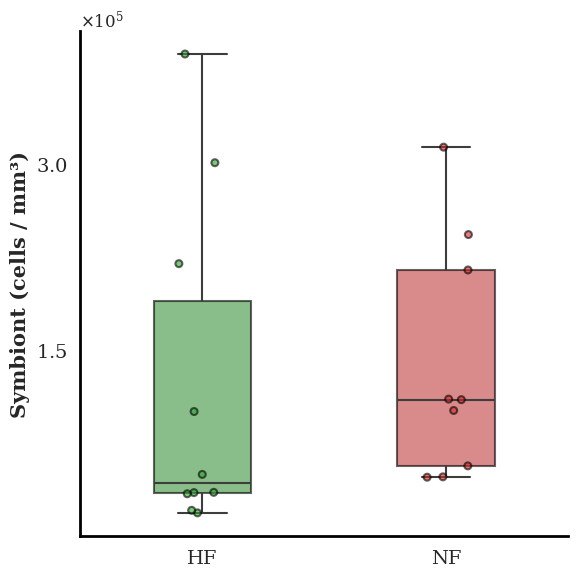

In [274]:
# --- BLOCK: SYMBIONT DENSITY ONLY PLOT ---
import matplotlib.ticker as ticker
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=global_fig_size)
plot_df = df_symbiont_clean.copy()
morph_order = ['HF', 'NF']

# Symbiont Density Plot (Cells per mm3)
sns.boxplot(
    data=plot_df,
    x='morph',
    y='Cells_per_mm3',
    order=morph_order,
    hue='morph',
    palette=variant_colors,
    ax=ax,
    showfliers=False,
    width=global_box_width,
    linewidth=global_line_width,
    boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor},
    legend=False
)

sns.stripplot(
    data=plot_df,
    x='morph',
    y='Cells_per_mm3',
    order=morph_order,
    hue='morph',
    palette=variant_colors,
    alpha=global_alpha,
    jitter=global_jitter,
    size=global_marker_size,
    ax=ax,
    edgecolor=global_edgecolor,
    linewidth=global_line_width,
    legend=False
)

# Layout Tweaks (No title, no X label, consistent Y label with parentheses and slash division)
ax.set_ylabel("Symbiont (cells / mm³)")
ax.set_xlabel("")

# Dynamic Significance Annotation (using the pre-calculated p_val / sig from earlier blocks)
if 'sig' in locals() and sig != 'n.s.':
    y_max = plot_df['Cells_per_mm3'].max()
    ax.text(0.5, y_max * 1.05,
            sig,
            ha='center', va='bottom',
            fontsize=global_asterisk_size,
            fontweight=global_asterisk_weight)

# Set scientific format to 10^5
formatter = ticker.ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((5, 5))
ax.yaxis.set_major_formatter(formatter)

# Set Y-axis tick spacing to 1.5 * 10^5 (150,000 cells/mm3)
ax.yaxis.set_major_locator(ticker.MultipleLocator(1.5e5))
ax.yaxis.get_offset_text().set_fontsize(12)

# Clean boundaries
sns.despine()
plt.tight_layout()
plt.savefig("Symbiont_Density_Only_Corrected.svg", format="svg", dpi=600)
plt.show()

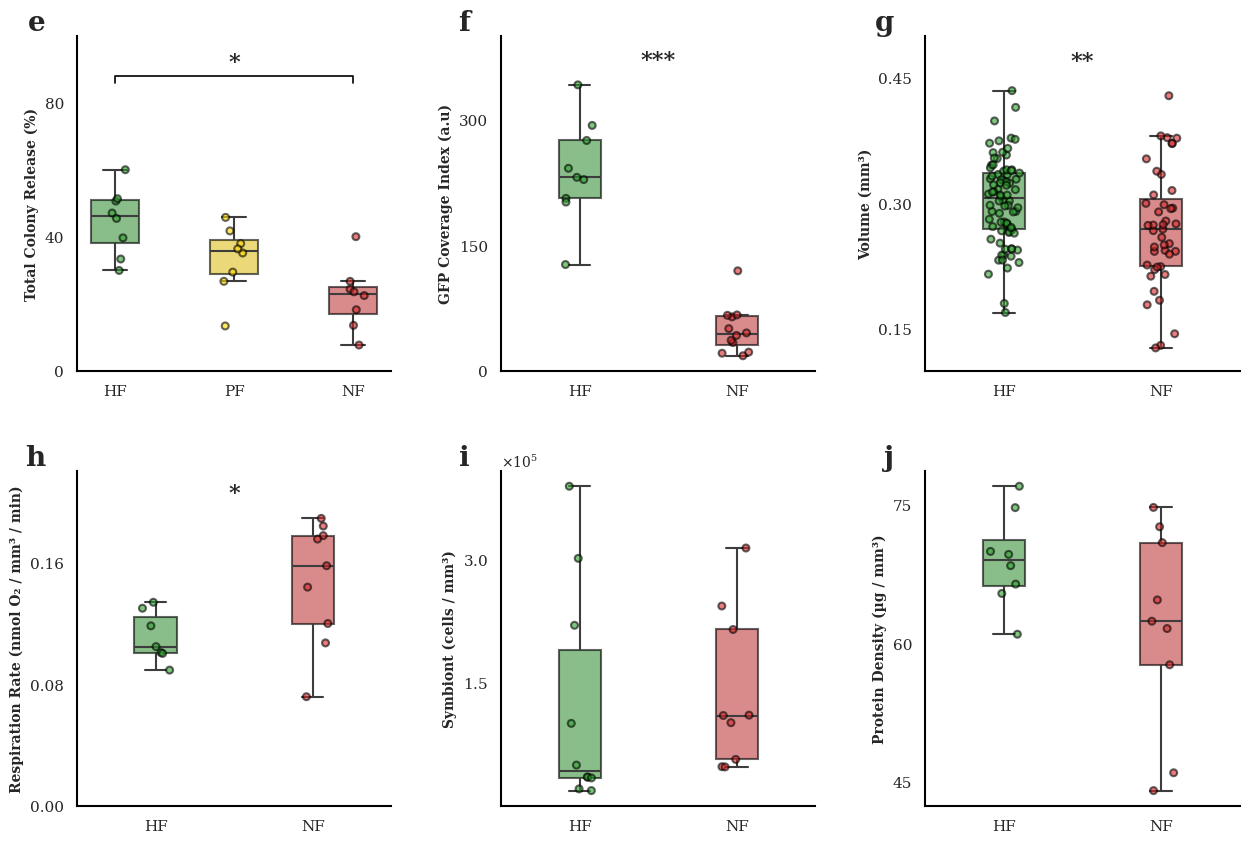

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [292]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
from scipy import stats
from google.colab import files

# Configure matplotlib for vectorized journal standards
plt.rcParams.update({
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": "Serif",
    "font.size": 12,
    "axes.labelsize": 10,
    "axes.labelweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.edgecolor": "black",
    "axes.linewidth": 1.5
})

# Using a 2x3 layout with constrained_layout to help maintain clean subplot proportions
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
plt.subplots_adjust(wspace=0.35, hspace=0.3)

# Standard width for boxes across subplots to ensure sizing symmetry
box_width_3_cat = 0.4
box_width_2_cat = 0.27

# Helper to draw single asterisk significance above HF/NF
def draw_unpaired_sig(ax, x1, x2, p_val, y_pos):
    sig_symbol = get_significance_label(p_val)
    if sig_symbol != 'n.s.':
        ax.text((x1 + x2) * 0.5, y_pos, sig_symbol,
                ha='center', va='bottom',
                fontsize=16, fontweight='bold')

# =========================================================================
# Panel e: Colony Release (%) (Row 1, Col 1)
# =========================================================================
ax_e = axes[0, 0]
plot_colors_e = {'HF': '#2ca02c', 'PF': '#FFD700', 'NF': '#d62728'}
morph_order_e = ['HF', 'PF', 'NF']

sns.boxplot(
    data=df_filtered, x='morph', y='% from total coloney', order=morph_order_e,
    palette=plot_colors_e, hue='morph', width=box_width_3_cat, showfliers=False,
    linewidth=global_line_width, legend=False, ax=ax_e, dodge=False,
    boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor}
)
sns.stripplot(
    data=df_filtered, x='morph', y='% from total coloney', order=morph_order_e,
    hue='morph', palette=plot_colors_e, size=global_marker_size, jitter=global_jitter,
    alpha=global_alpha, zorder=5, legend=False, edgecolor=global_edgecolor,
    linewidth=global_line_width, ax=ax_e, dodge=False
)

# Pairwise Significance Bracket (HF vs NF)
if ('HF', 'NF') in pair_p_map:
    adj_p = pair_p_map[('HF', 'NF')]
    sig_symbol = get_significance_label(adj_p)
    if sig_symbol != 'n.s.':
        x1, x2 = 0, 2
        y_bar = 88.0  # Aligned with f and g ~90% relative axis height
        h_bracket = 2.0
        ax_e.plot([x1, x1, x2, x2], [y_bar - h_bracket, y_bar, y_bar, y_bar - h_bracket], color='black', lw=1.2)
        ax_e.text((x1 + x2) * 0.5, y_bar + 1.0, sig_symbol, ha='center', va='bottom', fontsize=16, fontweight='bold')

ax_e.set_ylabel("Total Colony Release (%)")
ax_e.set_xlabel("")
ax_e.set_ylim(0, 100) # Increased slightly to accommodate higher bracket
ax_e.yaxis.set_major_locator(plt.MaxNLocator(global_y_nbins))
ax_e.text(-0.1, 1.08, 'e', transform=ax_e.transAxes, fontsize=20, fontweight='bold', va='top', ha='right')
sns.despine(ax=ax_e)

# =========================================================================
# Panel f: GFP Coverage (Row 1, Col 2)
# =========================================================================
ax_f = axes[0, 1]
plot_order_f = ['HF', 'NF']
sns.boxplot(
    data=df_gfp, x='Variant', y='Intensity_per_µm2', order=plot_order_f, palette=variant_colors, hue='Variant',
    width=box_width_2_cat, showfliers=False, linewidth=global_line_width, legend=False, ax=ax_f, dodge=False,
    boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor}
)
sns.stripplot(
    data=df_gfp, x='Variant', y='Intensity_per_µm2', order=plot_order_f, hue='Variant', palette=variant_colors,
    size=global_marker_size, jitter=global_jitter, alpha=global_alpha, zorder=5,
    legend=False, edgecolor=global_edgecolor, linewidth=global_line_width, ax=ax_f, dodge=False
)

# Significance annotation
hf_gfp_vals = df_gfp[df_gfp['Variant'] == 'HF']['Intensity_per_µm2'].dropna()
nf_gfp_vals = df_gfp[df_gfp['Variant'] == 'NF']['Intensity_per_µm2'].dropna()
_, local_gfp_p = stats.ttest_ind(hf_gfp_vals, nf_gfp_vals, equal_var=True)
draw_unpaired_sig(ax_f, 0, 1, local_gfp_p, df_gfp['Intensity_per_µm2'].max() * 1.05)

ax_f.set_ylabel("GFP Coverage Index (a.u)")
ax_f.set_xlabel("")
ax_f.set_ylim(0, 400)
ax_f.yaxis.set_major_locator(plt.MaxNLocator(global_y_nbins))
ax_f.set_xlim(-0.5, 1.5)
ax_f.text(-0.1, 1.08, 'f', transform=ax_f.transAxes, fontsize=20, fontweight='bold', va='top', ha='right')
sns.despine(ax=ax_f)

# =========================================================================
# Panel g: Larval Biovolume (Row 1, Col 3)
# =========================================================================
ax_g = axes[0, 2]
plot_order_g = ['HF', 'NF']
sns.boxplot(
    data=df_planulae_clean, x='morph', y='Volume mm³', order=plot_order_g, hue='morph',
    palette=variant_colors, ax=ax_g, showfliers=False, legend=False, width=box_width_2_cat,
    boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor}, linewidth=global_line_width, dodge=False
)
sns.stripplot(
    data=df_planulae_clean, x='morph', y='Volume mm³', order=plot_order_g, hue='morph',
    palette=variant_colors, alpha=global_alpha, jitter=global_jitter, size=global_marker_size,
    ax=ax_g, legend=False, linewidth=global_line_width, edgecolor=global_edgecolor, dodge=False
)

# Significance annotation
hf_vol_vals = df_planulae_clean[df_planulae_clean['morph'] == 'HF']['Volume mm³'].dropna()
nf_vol_vals = df_planulae_clean[df_planulae_clean['morph'] == 'NF']['Volume mm³'].dropna()
_, local_vol_p = stats.ttest_ind(hf_vol_vals, nf_vol_vals, equal_var=True)
draw_unpaired_sig(ax_g, 0, 1, local_vol_p, df_planulae_clean['Volume mm³'].max() * 1.05)

ax_g.set_ylabel("Volume (mm³)")
ax_g.set_xlabel("")
ax_g.set_ylim(0.1, 0.5)
ax_g.yaxis.set_major_locator(ticker.MaxNLocator(nbins=global_y_nbins))
ax_g.set_xlim(-0.5, 1.5)
ax_g.text(-0.1, 1.08, 'g', transform=ax_g.transAxes, fontsize=20, fontweight='bold', va='top', ha='right')
sns.despine(ax=ax_g)

# =========================================================================
# Panel h: Volume-Normalized Respiration (Row 2, Col 1)
# =========================================================================
ax_h = axes[1, 0]
plot_order_h = ['HF', 'NF']
sns.boxplot(
    data=df_resp_final, x='Morph', y='Respiration_Rate_per_mm3', order=plot_order_h, palette=variant_colors,
    hue='Morph', width=box_width_2_cat, showfliers=False, linewidth=global_line_width,
    legend=False, ax=ax_h, boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor}, dodge=False
)
sns.stripplot(
    data=df_resp_final, x='Morph', y='Respiration_Rate_per_mm3', order=plot_order_h, hue='Morph', palette=variant_colors,
    size=global_marker_size, jitter=global_jitter, alpha=global_alpha, zorder=5,
    legend=False, edgecolor=global_edgecolor, linewidth=global_line_width, ax=ax_h, dodge=False
)

# Significance annotation
hf_resp_vals = df_resp_final[df_resp_final['Morph'] == 'HF']['Respiration_Rate_per_mm3'].dropna()
nf_resp_vals = df_resp_final[df_resp_final['Morph'] == 'NF']['Respiration_Rate_per_mm3'].dropna()
_, local_resp_p = stats.ttest_ind(hf_resp_vals, nf_resp_vals, equal_var=True)
draw_unpaired_sig(ax_h, 0, 1, local_resp_p, df_resp_final['Respiration_Rate_per_mm3'].max() * 1.05)

ax_h.set_ylabel("Respiration Rate (nmol O₂ / mm³ / min)")
ax_h.set_xlabel("")
ax_h.set_ylim(0, 0.22)
ax_h.yaxis.set_major_locator(plt.MaxNLocator(global_y_nbins))
ax_h.set_xlim(-0.5, 1.5)
ax_h.text(-0.1, 1.08, 'h', transform=ax_h.transAxes, fontsize=20, fontweight='bold', va='top', ha='right')
sns.despine(ax=ax_h)

# =========================================================================
# Panel i: Volume-Normalized Symbiont Density (Row 2, Col 2)
# =========================================================================
ax_i = axes[1, 1]
plot_df_i = df_symbiont_clean.copy()
morph_order_i = ['HF', 'NF']

sns.boxplot(
    data=plot_df_i, x='morph', y='Cells_per_mm3', order=morph_order_i, hue='morph',
    palette=variant_colors, ax=ax_i, showfliers=False, width=box_width_2_cat,
    linewidth=global_line_width, boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor},
    legend=False, dodge=False
)
sns.stripplot(
    data=plot_df_i, x='morph', y='Cells_per_mm3', order=morph_order_i, hue='morph',
    palette=variant_colors, alpha=global_alpha, jitter=global_jitter, size=global_marker_size,
    ax=ax_i, edgecolor=global_edgecolor, linewidth=global_line_width, legend=False, dodge=False
)

# Significance Annotation (using local Mann-Whitney U for consistency)
hf_sym_vals = plot_df_i[plot_df_i['morph'] == 'HF']['Cells_per_mm3'].dropna()
nf_sym_vals = plot_df_i[plot_df_i['morph'] == 'NF']['Cells_per_mm3'].dropna()
_, local_sym_p = stats.mannwhitneyu(hf_sym_vals, nf_sym_vals, alternative='two-sided')
draw_unpaired_sig(ax_i, 0, 1, local_sym_p, plot_df_i['Cells_per_mm3'].max() * 1.05)

ax_i.set_ylabel("Symbiont (cells / mm³)")
ax_i.set_xlabel("")

# Apply Scientific Formatting (10^5 multiplier rules)
formatter_i = ticker.ScalarFormatter(useMathText=True)
formatter_i.set_scientific(True)
formatter_i.set_powerlimits((5, 5))
ax_i.yaxis.set_major_formatter(formatter_i)
ax_i.yaxis.set_major_locator(ticker.MultipleLocator(1.5e5))
ax_i.yaxis.get_offset_text().set_fontsize(10)
ax_i.set_xlim(-0.5, 1.5)

ax_i.text(-0.1, 1.08, 'i', transform=ax_i.transAxes, fontsize=20, fontweight='bold', va='top', ha='right')
sns.despine(ax=ax_i)

# =========================================================================
# Panel j: Volume-Normalized Host Protein Density (Row 2, Col 3)
# =========================================================================
ax_j = axes[1, 2]
plot_order_j = ['HF', 'NF']
sns.boxplot(
    data=df_prot_clean, x='morph', y='Protein_Density_ug_mm3', order=plot_order_j, hue='morph',
    palette=variant_colors, width=box_width_2_cat, showfliers=False, linewidth=global_line_width,
    legend=False, ax=ax_j, boxprops={'alpha': global_alpha, 'edgecolor': global_edgecolor}, dodge=False
)
sns.stripplot(
    data=df_prot_clean, x='morph', y='Protein_Density_ug_mm3', order=plot_order_j, hue='morph',
    palette=variant_colors, size=global_marker_size, jitter=global_jitter, alpha=global_alpha,
    zorder=5, legend=False, edgecolor=global_edgecolor, linewidth=global_line_width, ax=ax_j, dodge=False
)

# Significance annotation
hf_prot_vals = df_prot_clean[df_prot_clean['morph'] == 'HF']['Protein_Density_ug_mm3'].dropna()
nf_prot_vals = df_prot_clean[df_prot_clean['morph'] == 'NF']['Protein_Density_ug_mm3'].dropna()
_, local_prot_p = stats.ttest_ind(hf_prot_vals, nf_prot_vals, equal_var=True)
draw_unpaired_sig(ax_j, 0, 1, local_prot_p, df_prot_clean['Protein_Density_ug_mm3'].max() * 1.05)

ax_j.set_ylabel("Protein Density (µg / mm³)")
ax_j.set_xlabel("")
ax_j.yaxis.set_major_locator(plt.MaxNLocator(global_y_nbins))
ax_j.set_xlim(-0.5, 1.5)
ax_j.text(-0.1, 1.08, 'j', transform=ax_j.transAxes, fontsize=20, fontweight='bold', va='top', ha='right')
sns.despine(ax=ax_j)

# Save and Download outputs
plt.savefig("Figure1_panels_e_j.pdf", format="pdf", dpi=600, bbox_inches='tight')
plt.savefig("Figure1_panels_e_j.svg", format="svg", dpi=600, bbox_inches='tight')
plt.show()

try:
    files.download("Figure1_panels_e_j.pdf")
    files.download("Figure1_panels_e_j.svg")
except Exception as e:
    print("Automatic file downloading failed or was bypassed:", e)


## Additinal Info

In [275]:
import pandas as pd

# Helper to calculate stats per group
def get_stats(df, group_col, val_col, morphs=['HF', 'NF']):
    stats_dict = {}
    for m in morphs:
        data = df[df[group_col] == m][val_col]
        stats_dict[f'{m}_Mean'] = data.mean()
        stats_dict[f'{m}_SD'] = data.std()
        stats_dict[f'{m}_N'] = data.count()
    return stats_dict

# Compile results into a list
summary_data = []

# 1. Parental Investment (%)
p_a = 0.0195
stats_a = get_stats(df_filtered, 'morph', '% from total coloney')
summary_data.append({'Panel': 'a', 'Metric': 'Parental Investment (%)', **stats_a, 'p-value': p_a})

# 2. GFP Intensity
p_b = 1.1467e-08
stats_b = get_stats(df_gfp, 'Variant', 'Intensity_per_µm2')
summary_data.append({'Panel': 'b', 'Metric': 'GFP Intensity', **stats_b, 'p-value': p_b})

# 3. Planulae Volume
p_c = 3.21720e-03
stats_c = get_stats(df_planulae_clean, 'morph', 'Volume mm³')
summary_data.append({'Panel': 'c', 'Metric': 'Volume (mm3)', **stats_c, 'p-value': p_c})

# 4. Respiration Rate
p_d = 0.0426
stats_d = get_stats(df_resp_final, 'Morph', 'Respiration_Rate_per_mm3')
summary_data.append({'Panel': 'd', 'Metric': 'Respiration Rate', **stats_d, 'p-value': p_d})

# 5. Protein Density
p_e = 0.0996
stats_e = get_stats(df_prot_clean, 'morph', 'Protein_Density_ug_mm3')
summary_data.append({'Panel': 'e', 'Metric': 'Protein Density', **stats_e, 'p-value': p_e})

# 6. Symbiont Density
p_f = 0.2057 # Actual Mann-Whitney U test result
stats_f = get_stats(df_symbiont_clean, 'morph', 'Cells_per_mm3')
summary_data.append({'Panel': 'f', 'Metric': 'Symbiont Density', **stats_f, 'p-value': p_f})

# Create DataFrame
full_stats_df = pd.DataFrame(summary_data)

# Display the table
print("Full Statistical Summary for Integrated Panels")
display(full_stats_df.round(4))

Full Statistical Summary for Integrated Panels


,Panel,Metric,HF_Mean,HF_SD,HF_N,NF_Mean,NF_SD,NF_N,p-value
0,a,Parental Investment (%),44.6753,9.9498,8,22.0331,9.6116,8,0.0195
1,b,GFP Intensity,238.2205,61.2359,9,48.6032,28.1703,12,0.0000
2,c,Volume (mm3),0.3024,0.0505,82,0.2698,0.0691,43,0.0032
3,d,Respiration Rate,0.1109,0.0167,7,0.1473,0.0403,9,0.0426
4,e,Protein Density,69.0446,5.1002,8,61.6111,10.9398,9,0.0996
5,f,Symbiont Density,120223.3980,134204.8925,10,138190.2526,95909.5201,9,0.2057


In [276]:
import sys
import pandas
import numpy
import matplotlib
import seaborn
import scipy

# Specifically check versions of libraries used in the notebook
used_libs = {
    "pandas": pandas.__version__,
    "numpy": numpy.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": seaborn.__version__,
    "scipy": scipy.__version__,
    "python": sys.version
}

print("--- Versions of libraries used in this notebook ---")
for lib, version in used_libs.items():
    print(f"{lib}: {version}")

print("\n--- Full environment package list ---")


--- Versions of libraries used in this notebook ---
pandas: 2.2.3
numpy: 2.4.6
matplotlib: 3.10.0
seaborn: 0.13.2
scipy: 1.16.3
python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

--- Full environment package list ---


In [277]:
all_outliers_summary = []

# 1. Planulae Volume - Aspect Ratio Filtering
if not df_removed_ratio.empty:
    df_temp = df_removed_ratio[['morph', 'Aspect_Ratio']].copy()
    df_temp['Metric'] = 'Planulae Volume (Aspect Ratio)'
    df_temp['stage'] = 'Geometric Filtering'
    df_temp['treatment'] = 'Aspect Ratio Filtering'
    df_temp['reason'] = 'Removed as Aspect Ratio < 2.5'
    df_temp.rename(columns={'Aspect_Ratio': 'value'}, inplace=True)
    all_outliers_summary.append(df_temp[['Metric', 'stage', 'treatment', 'morph', 'value', 'reason']])

# 2. Planulae Volume - 1.5 IQR Outlier Removal
if not df_planulae_outliers.empty:
    df_temp = df_planulae_outliers[['morph', 'Volume mm³']].copy()
    df_temp['Metric'] = 'Planulae Volume'
    df_temp['stage'] = '1.5xIQR Outlier Removal'
    df_temp['treatment'] = 'Volume mm³'
    df_temp['reason'] = 'Removed as 1.5xIQR outlier'
    df_temp.rename(columns={'Volume mm³': 'value'}, inplace=True)
    all_outliers_summary.append(df_temp[['Metric', 'stage', 'treatment', 'morph', 'value', 'reason']])

# 3. Respiration Rate - 1.5 IQR Outlier Removal
if not df_resp_outliers.empty:
    df_temp = df_resp_outliers[['Morph', 'Respiration_Rate_per_mm3']].copy()
    df_temp['Metric'] = 'Respiration Rate'
    df_temp['stage'] = '1.5xIQR Outlier Removal'
    df_temp['treatment'] = 'Respiration_Rate_per_mm3'
    df_temp['reason'] = 'Removed as 1.5xIQR outlier'
    df_temp.rename(columns={'Morph': 'morph', 'Respiration_Rate_per_mm3': 'value'}, inplace=True)
    all_outliers_summary.append(df_temp[['Metric', 'stage', 'treatment', 'morph', 'value', 'reason']])

# 4. Protein Density - 1.5 IQR Outlier Removal
if not df_prot_removed.empty:
    df_temp = df_prot_removed[['morph', 'Protein_Density_ug_mm3']].copy()
    df_temp['Metric'] = 'Protein Density'
    df_temp['stage'] = '1.5xIQR Outlier Removal'
    df_temp['treatment'] = 'Protein_Density_ug_mm3'
    df_temp['reason'] = 'Removed as 1.5xIQR outlier'
    df_temp.rename(columns={'Protein_Density_ug_mm3': 'value'}, inplace=True)
    all_outliers_summary.append(df_temp[['Metric', 'stage', 'treatment', 'morph', 'value', 'reason']])

# 5. Symbiont Cell Count - Biological Outlier Removal
if not df_symbiont_outliers.empty:
    df_temp = df_symbiont_outliers[['morph', 'Cells_per_mm3']].copy()
    df_temp['Metric'] = 'Symbiont Density'
    df_temp['stage'] = 'Biological Outlier Removal'
    df_temp['treatment'] = 'Cells_per_mm3'
    df_temp['reason'] = 'Removed as 1.5xIQR outlier'
    df_temp.rename(columns={'Cells_per_mm3': 'value'}, inplace=True)
    all_outliers_summary.append(df_temp[['Metric', 'stage', 'treatment', 'morph', 'value', 'reason']])

# Concatenate all summaries into a single DataFrame
if all_outliers_summary:
    final_outliers_df = pd.concat(all_outliers_summary, ignore_index=True)
    display(final_outliers_df)
else:
    print("No outliers were removed across all analyses.")

,Metric,stage,treatment,morph,value,reason
0,Planulae Volume (Aspect Ratio),Geometric Filtering,Aspect Ratio Filtering,HF,1.783012,Removed as Aspect Ratio < 2.5
1,Planulae Volume (Aspect Ratio),Geometric Filtering,Aspect Ratio Filtering,HF,2.254283,Removed as Aspect Ratio < 2.5
2,Planulae Volume (Aspect Ratio),Geometric Filtering,Aspect Ratio Filtering,NF,2.248411,Removed as Aspect Ratio < 2.5
3,Planulae Volume (Aspect Ratio),Geometric Filtering,Aspect Ratio Filtering,NF,1.653646,Removed as Aspect Ratio < 2.5
4,Planulae Volume,1.5xIQR Outlier Removal,Volume mm³,HF,0.459000,Removed as 1.5xIQR outlier
5,Planulae Volume,1.5xIQR Outlier Removal,Volume mm³,HF,0.479500,Removed as 1.5xIQR outlier
6,Planulae Volume,1.5xIQR Outlier Removal,Volume mm³,HF,0.475800,Removed as 1.5xIQR outlier
7,Planulae Volume,1.5xIQR Outlier Removal,Volume mm³,HF,0.460900,Removed as 1.5xIQR outlier
8,Planulae Volume,1.5xIQR Outlier Removal,Volume mm³,HF,0.160100,Removed as 1.5xIQR outlier
9,Planulae Volume,1.5xIQR Outlier Removal,Volume mm³,HF,0.149000,Removed as 1.5xIQR outlier


In [278]:
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
from google.colab import files

# --- TASK 1: OUTLIER & REMOVED SAMPLES AUDIT ---
audit_rows = []

def add_audit_rows(frame, metric, value_col, reason, id_cols=(), morph_col=None, condition="Overall"):
    if frame is None or frame.empty or value_col not in frame.columns:
        return
    for idx, row in frame.iterrows():
        sample_id = next((row[col] for col in id_cols if col in frame.columns and pd.notna(row[col])), idx)
        morph = row[morph_col] if morph_col and morph_col in frame.columns else "N/A"
        audit_rows.append({
            "Sample_ID": sample_id,
            "Metric": metric,
            "Condition_Treatment": condition,
            "Morphotype": morph,
            "Excluded_Value": row[value_col],
            "Reason_for_Removal": reason
        })

if "df_removed_ratio" in globals():
    add_audit_rows(df_removed_ratio, "Planulae Volume (mm³)", "Volume mm³", "Aspect Ratio < 2.5 (geometric filter)", id_cols=("no", "Label"), morph_col="morph")
if "df_planulae_outliers" in globals():
    add_audit_rows(df_planulae_outliers, "Planulae Volume (mm³)", "Volume mm³", "1.5x IQR outlier filter", id_cols=("no", "Label"), morph_col="morph")
if "df_resp_outliers" in globals():
    add_audit_rows(df_resp_outliers, "Respiration Rate (nmol O₂ mm⁻³ min⁻¹)", "Respiration_Rate_per_mm3", "1.5x IQR outlier filter", id_cols=("Well",), morph_col="Morph")
if "df_prot_removed" in globals():
    add_audit_rows(df_prot_removed, "Protein Density (µg mm⁻³)", "Protein_Density_ug_mm3", "1.5x IQR outlier filter", id_cols=("sample id",), morph_col="morph")
if "df_symbiont_outliers" in globals():
    add_audit_rows(df_symbiont_outliers, "Symbiont Density (cells mm⁻³)", "Cells_per_mm3", "1.5x IQR biological outlier filter", id_cols=("Sample No",), morph_col="morph")

try:
    _gfp_raw = pd.read_csv("GFP_raw_sum_normalized.csv")
    _gfp_raw = _gfp_raw[_gfp_raw["Variant"].isin(["HF", "NF"])].copy()
    _gfp_col = "Intensity_per_µm2"
    _gfp_q1, _gfp_q3 = _gfp_raw[_gfp_col].quantile([0.25, 0.75])
    _gfp_iqr = _gfp_q3 - _gfp_q1
    _gfp_removed = _gfp_raw[(_gfp_raw[_gfp_col] < _gfp_q1 - 1.5 * _gfp_iqr) | (_gfp_raw[_gfp_col] > _gfp_q3 + 1.5 * _gfp_iqr)]
    add_audit_rows(_gfp_removed, "GFP Intensity (a.u. µm⁻²)", _gfp_col, "1.5x IQR outlier filter", id_cols=("Sample_ID", "Sample ID", "sample id"), morph_col="Variant")
except Exception:
    pass

if "df_algae_data" in globals():
    _grid_cols = [c for c in df_algae_data.columns if c == "Counts..." or "Unnamed" in c]
    for idx, row in df_algae_data.iterrows():
        _grids = pd.to_numeric(row[_grid_cols], errors="coerce").dropna()
        if len(_grids) >= 4:
            _q1, _q3 = _grids.quantile([0.25, 0.75])
            _iqr = _q3 - _q1
            _removed_grids = _grids[(_grids < _q1 - 1.5 * _iqr) | (_grids > _q3 + 1.5 * _iqr)]
            for _value in _removed_grids:
                audit_rows.append({
                    "Sample_ID": row.get("Sample No", idx),
                    "Metric": "Hemocytometer grid count",
                    "Condition_Treatment": "Overall",
                    "Morphotype": row.get("morph", "N/A"),
                    "Excluded_Value": _value,
                    "Reason_for_Removal": "Technical artifact (per-sample grid IQR)"
                })

baseline_removed_samples_audit_df = pd.DataFrame(audit_rows)
baseline_removed_samples_audit_df.to_csv("baseline_removed_samples_audit.csv", index=False)

# --- TASK 2: STANDARDIZED DESCRIPTIVE & STATISTICAL TABLE ---
def compute_cohen_d_paired(diff):
    n = len(diff)
    mean_diff = diff.mean()
    std_diff = diff.std(ddof=1)
    dz = mean_diff / std_diff if std_diff != 0 else 0
    se = np.sqrt((1/n) + (dz**2 / (2*n)))
    return dz, dz - 1.96*se, dz + 1.96*se

def compute_cohen_d_unpaired(x, y):
    nx, ny = len(x), len(y)
    pooled_std = np.sqrt(((nx - 1)*x.var(ddof=1) + (ny - 1)*y.var(ddof=1)) / (nx + ny - 2))
    d = (x.mean() - y.mean()) / pooled_std if pooled_std != 0 else 0
    se = np.sqrt(((nx + ny) / (nx * ny)) + (d**2 / (2 * (nx + ny))))
    return d, d - 1.96*se, d + 1.96*se

def compute_rank_biserial(x, y):
    n1, n2 = len(x), len(y)
    u_stat, _ = stats.mannwhitneyu(x, y, alternative='two-sided')
    r = 1 - (2 * u_stat) / (n1 * n2) if (n1 * n2) != 0 else 0
    return r, np.nan, np.nan

summary_rows = []

# Paired Release Data (Holm-Bonferroni correction)
if "df_pivot_pct" in globals() and "df_pivot_cnt" in globals():
    pairs = [('HF', 'PF'), ('PF', 'NF'), ('HF', 'NF')]
    raw_p_pct = []
    for m1, m2 in pairs:
        _, p = stats.ttest_rel(df_pivot_pct[m1], df_pivot_pct[m2])
        raw_p_pct.append(p)
    _, corrected_p_pct, _, _ = multipletests(raw_p_pct, alpha=0.05, method='holm')

    for idx, (m1, m2) in enumerate(pairs):
        h_vals = df_pivot_pct[m1]
        n_vals = df_pivot_pct[m2]
        diff = h_vals - n_vals
        dz, ci_l, ci_u = compute_cohen_d_paired(diff)

        summary_rows.append({
            "Metric / Parameter": f"Parental Investment % ({m1} vs {m2})",
            "Condition / Treatment": "Overall (Paired)",
            "N_HF": len(h_vals),
            "HF_Summary": f"{h_vals.mean():.2f} ± {h_vals.std():.2f} [med: {h_vals.median():.2f}]",
            "N_NF": len(n_vals),
            "NF_Summary": f"{n_vals.mean():.2f} ± {n_vals.std():.2f} [med: {n_vals.median():.2f}]",
            "Test_Used": "Paired t-test (Holm-Adjusted)",
            "Test_Statistic": f"{stats.ttest_rel(h_vals, n_vals).statistic:.4f}",
            "p_value": f"{corrected_p_pct[idx]:.4f}",
            "Significance": "***" if corrected_p_pct[idx] < 0.001 else "**" if corrected_p_pct[idx] < 0.01 else "*" if corrected_p_pct[idx] < 0.05 else "ns",
            "Effect_Size": f"dz = {dz:.4f}",
            "95%_CI": f"[{ci_l:.4f}, {ci_u:.4f}]"
        })

# Unpaired Datasets
unpaired_specs = [
    ("GFP Intensity (a.u. µm⁻²)", "df_gfp", "Variant", "Intensity_per_µm2", "parametric", 2, "intensity"),
    ("Planulae Volume (mm³)", "df_planulae_clean", "morph", "Volume mm³", "parametric", 4, "volume"),
    ("Unpruned Respiration (nmol O₂ larva⁻¹ min⁻¹)", "df_respiration_corrected", "Morph", "Respiration_Rate_nmol_per_Planula", "parametric", 4, "rate"),
    ("Unpruned Respiration Normalized (nmol O₂ mm⁻³ min⁻¹)", "df_respiration_corrected", "Morph", "Respiration_Rate_per_mm3", "parametric", 4, "rate"),
    ("IQR-Pruned Respiration (nmol O₂ mm⁻³ min⁻¹)", "df_resp_final", "Morph", "Respiration_Rate_per_mm3", "parametric", 4, "rate"),
    ("Protein Density (µg mm⁻³)", "df_prot_clean", "morph", "Protein_Density_ug_mm3", "parametric", 2, "protein"),
    ("Symbiont Cells per Planula", "df_symbiont_clean", "morph", "Cells_per_Planula", "non-parametric", 2, "scientific"),
    ("Symbiont Density (cells mm⁻³)", "df_symbiont_clean", "morph", "Cells_per_mm3", "non-parametric", 2, "scientific")
]

for metric, df_name, group_col, val_col, test_family, dec, format_type in unpaired_specs:
    if df_name not in globals():
        continue
    data = globals()[df_name]
    h_vals = pd.to_numeric(data.loc[data[group_col] == 'HF', val_col], errors='coerce').dropna()
    n_vals = pd.to_numeric(data.loc[data[group_col] == 'NF', val_col], errors='coerce').dropna()

    if len(h_vals) == 0 or len(n_vals) == 0:
        continue

    if test_family == "parametric":
        res = stats.ttest_ind(h_vals, n_vals, equal_var=True)
        stat, p = res.statistic, res.pvalue
        test_name = "Independent t-test"
        es_val, ci_l, ci_u = compute_cohen_d_unpaired(h_vals, n_vals)
        es_label = f"d = {es_val:.4f}"
        ci_label = f"[{ci_l:.4f}, {ci_u:.4f}]"
    else:
        res = stats.mannwhitneyu(h_vals, n_vals, alternative='two-sided')
        stat, p = res.statistic, res.pvalue
        test_name = "Mann-Whitney U"
        es_val, _, _ = compute_rank_biserial(h_vals, n_vals)
        es_label = f"r = {es_val:.4f}"
        ci_label = "N/A"

    def fmt(v):
        if format_type == "scientific":
            return f"{v:.2e}"
        elif dec == 4:
            return f"{v:.4f}"
        else:
            return f"{v:.2f}"

    summary_rows.append({
        "Metric / Parameter": metric,
        "Condition / Treatment": "Overall",
        "N_HF": len(h_vals),
        "HF_Summary": f"{fmt(h_vals.mean())} ± {fmt(h_vals.std())} [med: {fmt(h_vals.median())}]",
        "N_NF": len(n_vals),
        "NF_Summary": f"{fmt(n_vals.mean())} ± {fmt(n_vals.std())} [med: {fmt(n_vals.median())}]",
        "Test_Used": test_name,
        "Test_Statistic": f"{stat:.4f}",
        "p_value": f"{p:.4e}" if p < 0.0001 else f"{p:.4f}",
        "Significance": "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns",
        "Effect_Size": es_label,
        "95%_CI": ci_label
    })

baseline_physiology_summary = pd.DataFrame(summary_rows)
baseline_physiology_summary.to_csv("baseline_physiology_summary.csv", index=False)

print("=== REMOVED SAMPLES AUDIT ===")
display(baseline_removed_samples_audit_df.head())
print("\n=== PHYSIOLOGY SUMMARY TABLE ===")
display(baseline_physiology_summary)

try:
    files.download("baseline_removed_samples_audit.csv")
    files.download("baseline_physiology_summary.csv")
except Exception:
    pass

=== REMOVED SAMPLES AUDIT ===


,Sample_ID,Metric,Condition_Treatment,Morphotype,Excluded_Value,Reason_for_Removal
0,51,Planulae Volume (mm³),Overall,HF,0.4819,Aspect Ratio < 2.5 (geometric filter)
1,82,Planulae Volume (mm³),Overall,HF,0.1930,Aspect Ratio < 2.5 (geometric filter)
2,95,Planulae Volume (mm³),Overall,NF,0.1637,Aspect Ratio < 2.5 (geometric filter)
3,102,Planulae Volume (mm³),Overall,NF,0.2572,Aspect Ratio < 2.5 (geometric filter)
4,6,Planulae Volume (mm³),Overall,HF,0.4590,1.5x IQR outlier filter



=== PHYSIOLOGY SUMMARY TABLE ===


,Metric / Parameter,Condition / Treatment,N_HF,HF_Summary,N_NF,NF_Summary,Test_Used,Test_Statistic,p_value,Significance,Effect_Size,95%_CI
0,Parental Investment % (HF vs PF),Overall (Paired),8,44.68 ± 9.95 [med: 46.26],8,33.29 ± 10.13 [med: 35.75],Paired t-test (Holm-Adjusted),1.8262,0.2084,ns,dz = 0.6457,"[-0.1161, 1.4074]"
1,Parental Investment % (PF vs NF),Overall (Paired),8,33.29 ± 10.13 [med: 35.75],8,22.03 ± 9.61 [med: 22.97],Paired t-test (Holm-Adjusted),1.8667,0.2084,ns,dz = 0.6600,"[-0.1047, 1.4247]"
2,Parental Investment % (HF vs NF),Overall (Paired),8,44.68 ± 9.95 [med: 46.26],8,22.03 ± 9.61 [med: 22.97],Paired t-test (Holm-Adjusted),3.8263,0.0195,*,dz = 1.3528,"[0.3938, 2.3117]"
3,GFP Intensity (a.u. µm⁻²),Overall,9,238.22 ± 61.24 [med: 230.92],12,48.60 ± 28.17 [med: 43.50],Independent t-test,9.5246,1.1467e-08,***,d = 4.1999,"[2.6636, 5.7363]"
4,Planulae Volume (mm³),Overall,82,0.3024 ± 0.0505 [med: 0.3058],43,0.2698 ± 0.0691 [med: 0.2690],Independent t-test,3.0052,0.0032,**,d = 0.5658,"[0.1902, 0.9415]"
5,Unpruned Respiration (nmol O₂ larva⁻¹ min⁻¹),Overall,10,0.0400 ± 0.0215 [med: 0.0337],10,0.0436 ± 0.0159 [med: 0.0449],Independent t-test,-0.4279,0.6738,ns,d = -0.1914,"[-1.0699, 0.6872]"
6,Unpruned Respiration Normalized (nmol O₂ mm⁻³ ...,Overall,10,0.1322 ± 0.0710 [med: 0.1114],10,0.1615 ± 0.0590 [med: 0.1665],Independent t-test,-1.0059,0.3278,ns,d = -0.4498,"[-1.3374, 0.4377]"
7,IQR-Pruned Respiration (nmol O₂ mm⁻³ min⁻¹),Overall,7,0.1109 ± 0.0167 [med: 0.1046],9,0.1473 ± 0.0403 [med: 0.1578],Independent t-test,-2.2307,0.0426,*,d = -1.1242,"[-2.1859, -0.0624]"
8,Protein Density (µg mm⁻³),Overall,8,69.04 ± 5.10 [med: 69.00],9,61.61 ± 10.94 [med: 62.38],Independent t-test,1.7552,0.0996,ns,d = 0.8529,"[-0.1417, 1.8475]"
9,Symbiont Cells per Planula,Overall,10,3.64e+04 ± 4.06e+04 [med: 1.28e+04],9,3.73e+04 ± 2.59e+04 [med: 2.96e+04],Mann-Whitney U,34.0000,0.3913,ns,r = 0.2444,N/A


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>